# Tái lập kết quả chính

Notebook này **tính lại** các con số trong báo cáo từ mô hình cuối của từng phương pháp, không chép lại số:

- `RETRAIN = False` (mặc định): nạp mô hình đã lưu (`results/<mô hình>/model.pkl`), dự đoán lại trên train / val / test rồi
  tính accuracy, precision, recall, F1, ma trận nhầm lẫn, log-loss... Mất vài phút.
- `RETRAIN = True`: huấn luyện lại mọi mô hình cuối theo đúng cấu hình đã chốt (`results/<mô hình>/final_metrics.json`),
  lưu lại rồi làm như trên. Khoảng 35–40 phút trên CPU.

Random Forest (khoảng 220 MB) không có trong Git nên lần chạy đầu luôn tự huấn luyện lại nó (vài giây).
Mỗi bảng có cột **khớp**: ma trận nhầm lẫn tính lại trùng từng ô với số đã ghi.

Phần dò siêu tham số (các thí nghiệm E0, E1, ... trong `src/experiments/`, khoảng 2 giờ) không chạy lại ở đây:
biểu đồ và bảng của chúng được đọc từ `results/<mô hình>/`. Chạy lại toàn bộ: các lệnh ở mục *Chạy thí nghiệm* của
`README.md`. Tái lập cần cùng seed (`src/config.py`) và cùng số luồng BLAS (8): đổi số luồng làm MLP, CNN huấn
luyện ra trọng số hơi khác.

Dữ liệu MNIST có sẵn trong `data/raw/` (xem README, mục Dữ liệu).

In [1]:
RETRAIN = False          # True: huấn luyện lại mọi mô hình cuối (~35–40 phút)
BLAS_THREADS = 8         # phải bằng số luồng lúc chạy thí nghiệm

In [2]:
import json
import sys
import tempfile
import time
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
for p in [ROOT, *ROOT.parents]:                     # tìm gốc repo, để chạy được từ thư mục con
    if (p / "src" / "config.py").is_file():
        ROOT = p
        break
sys.path.insert(0, str(ROOT))

from src.config import BASELINE_KEY, DISPLAY_NAMES, EDA_CLOSE_PAIRS, ENSEMBLE_KEY, MODEL_KEYS, SPLITS
from src.data.preprocess import load_splits
from src.evaluation.analysis import pair_errors, probabilistic_scores, share_in_pairs
from src.evaluation.metrics import classification_scores
from src.evaluation.results_io import RESULTS_DIR, load_final_metrics
from src.experiments.final_models import ensemble_proba, get_model
from src.plots.common import plot_confusion_splits

KEYS = (BASELINE_KEY, *MODEL_KEYS, ENSEMBLE_KEY)
recorded = {k: load_final_metrics(k) for k in KEYS}
missing = [k for k in KEYS if recorded[k] is None]
assert not missing, f"Chưa có kết quả: {missing}. Chạy các script ở README trước."
assert not any(recorded[k].get("quick") for k in KEYS), "Có kết quả --quick: không dùng cho báo cáo."
splits = load_splits()


def table(header, rows):
    """Bảng Markdown (không cần pandas)."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def fig(key, name, width=900):
    path = RESULTS_DIR / key / "figures" / name
    display(Image(filename=str(path), width=width) if path.is_file() else Markdown(f"*(chưa có `{name}`)*"))


def num(v, d=4):
    return "—" if v is None else f"{v:.{d}f}".replace(".", ",")

## 1. Nạp hoặc huấn luyện lại mô hình cuối, dự đoán lại

In [3]:
proba, pred_time = {}, {}
with threadpool_limits(BLAS_THREADS, user_api="blas"):
    for k in KEYS:
        t0 = time.perf_counter()
        if k == ENSEMBLE_KEY:
            proba[k] = ensemble_proba(splits, retrain=RETRAIN)
        else:
            model = get_model(k, splits, retrain=RETRAIN)
            if hasattr(model, "predict_proba") and k != BASELINE_KEY:
                proba[k] = {s: model.predict_proba(splits[s][0]) for s in SPLITS}
            else:                                   # tâm gần nhất không có xác suất: one-hot của dự đoán
                proba[k] = {s: np.eye(10)[model.predict(splits[s][0])] for s in SPLITS}
        pred_time[k] = time.perf_counter() - t0
        print(f"{DISPLAY_NAMES[k]:<28} dự đoán lại 3 tập: {pred_time[k]:.1f} s")

scores = {k: {s: classification_scores(splits[s][1], proba[k][s].argmax(axis=1)) for s in SPLITS} for k in KEYS}
match = {k: all(np.array_equal(scores[k][s]["confusion_matrix"], np.asarray(recorded[k]["splits"][s]["confusion_matrix"]))
                for s in SPLITS) for k in KEYS}
table(["Mô hình", "khớp final_metrics.json (cả 3 tập)"], [(DISPLAY_NAMES[k], "có" if match[k] else "**LỆCH**") for k in KEYS])
assert all(match.values()), "Có mô hình không tái lập đúng: kiểm tra BLAS_THREADS và phiên bản thư viện."


Tâm gần nhất (baseline)      dự đoán lại 3 tập: 0.1 s


Naive Bayes                  dự đoán lại 3 tập: 0.5 s


Logistic Regression          dự đoán lại 3 tập: 0.6 s


MLP                          dự đoán lại 3 tập: 1.0 s


C:\Users\nguye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\nguye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Random Forest                dự đoán lại 3 tập: 1.5 s


CNN                          dự đoán lại 3 tập: 21.6 s


C:\Users\nguye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


C:\Users\nguye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


Gộp mô hình (soft voting)    dự đoán lại 3 tập: 112.6 s


| Mô hình | khớp final_metrics.json (cả 3 tập) |
|---|---|
| Tâm gần nhất (baseline) | có |
| Naive Bayes | có |
| Logistic Regression | có |
| MLP | có |
| Random Forest | có |
| CNN | có |
| Gộp mô hình (soft voting) | có |

## 2. Độ đo trên train / validation / test

Đúng yêu cầu của đề: accuracy, precision, recall, F1 (macro), ma trận nhầm lẫn trên cả ba tập. Mọi số dưới đây tính
lại từ dự đoán ở trên. `fit (s)` là thời gian huấn luyện đã ghi lúc chạy thí nghiệm (định nghĩa chung ở
`results/README.md`), kèm số luồng: so thời gian phải kèm con số này.

In [4]:
for s in SPLITS:
    display(Markdown(f"**{s}**"))
    table(["Mô hình", "Accuracy", "Precision", "Recall", "F1", "fit (s)", "luồng"],
          [(DISPLAY_NAMES[k], num(m["accuracy"]), num(m["precision_macro"]), num(m["recall_macro"]), num(m["f1_macro"]),
            num(recorded[k]["fit_time"], 1), recorded[k]["runtime"]["n_jobs"]) for k in KEYS for m in [scores[k][s]]])

**train**

| Mô hình | Accuracy | Precision | Recall | F1 | fit (s) | luồng |
|---|---|---|---|---|---|---|
| Tâm gần nhất (baseline) | 0,8080 | 0,8116 | 0,8046 | 0,8059 | 0,2 | 1 |
| Naive Bayes | 0,8247 | 0,8317 | 0,8216 | 0,8233 | 0,5 | 1 |
| Logistic Regression | 0,9281 | 0,9274 | 0,9270 | 0,9271 | 2,7 | 8 |
| MLP | 1,0000 | 1,0000 | 1,0000 | 1,0000 | 247,7 | 8 |
| Random Forest | 1,0000 | 1,0000 | 1,0000 | 1,0000 | 7,3 | 14 |
| CNN | 0,9963 | 0,9963 | 0,9963 | 0,9963 | 273,1 | 8 |
| Gộp mô hình (soft voting) | 0,9993 | 0,9993 | 0,9993 | 0,9993 | 1452,4 | 8 |

**val**

| Mô hình | Accuracy | Precision | Recall | F1 | fit (s) | luồng |
|---|---|---|---|---|---|---|
| Tâm gần nhất (baseline) | 0,8048 | 0,8103 | 0,8014 | 0,8031 | 0,2 | 1 |
| Naive Bayes | 0,8229 | 0,8317 | 0,8200 | 0,8220 | 0,5 | 1 |
| Logistic Regression | 0,9197 | 0,9191 | 0,9188 | 0,9188 | 2,7 | 8 |
| MLP | 0,9831 | 0,9830 | 0,9830 | 0,9830 | 247,7 | 8 |
| Random Forest | 0,9694 | 0,9693 | 0,9693 | 0,9693 | 7,3 | 14 |
| CNN | 0,9855 | 0,9854 | 0,9855 | 0,9854 | 273,1 | 8 |
| Gộp mô hình (soft voting) | 0,9913 | 0,9913 | 0,9913 | 0,9913 | 1452,4 | 8 |

**test**

| Mô hình | Accuracy | Precision | Recall | F1 | fit (s) | luồng |
|---|---|---|---|---|---|---|
| Tâm gần nhất (baseline) | 0,8198 | 0,8230 | 0,8167 | 0,8178 | 0,2 | 1 |
| Naive Bayes | 0,8356 | 0,8431 | 0,8325 | 0,8342 | 0,5 | 1 |
| Logistic Regression | 0,9238 | 0,9229 | 0,9226 | 0,9227 | 2,7 | 8 |
| MLP | 0,9836 | 0,9835 | 0,9835 | 0,9835 | 247,7 | 8 |
| Random Forest | 0,9668 | 0,9666 | 0,9665 | 0,9666 | 7,3 | 14 |
| CNN | 0,9882 | 0,9881 | 0,9882 | 0,9881 | 273,1 | 8 |
| Gộp mô hình (soft voting) | 0,9915 | 0,9915 | 0,9915 | 0,9915 | 1452,4 | 8 |

Ma trận nhầm lẫn train | val | test, vẽ lại từ dự đoán (khung cam: 5 cặp có tâm gần nhau nhất, EDA 3.1):

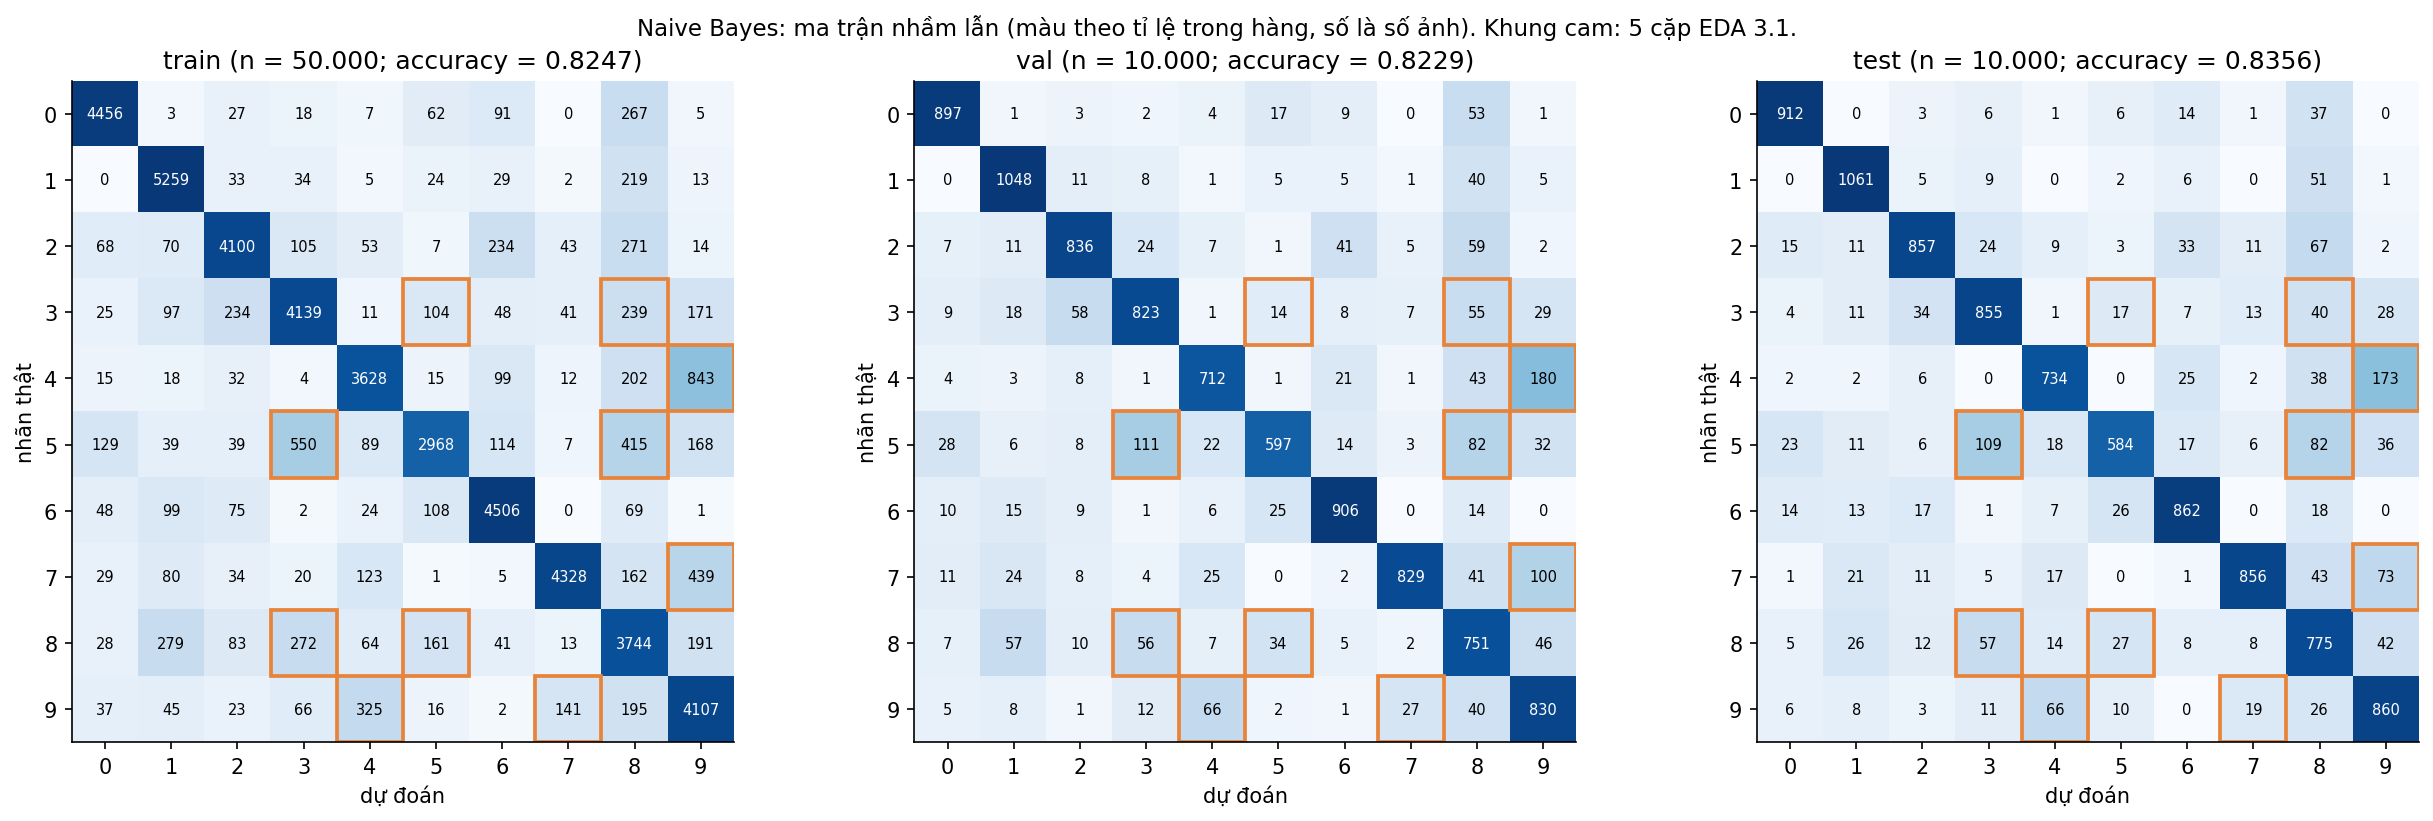

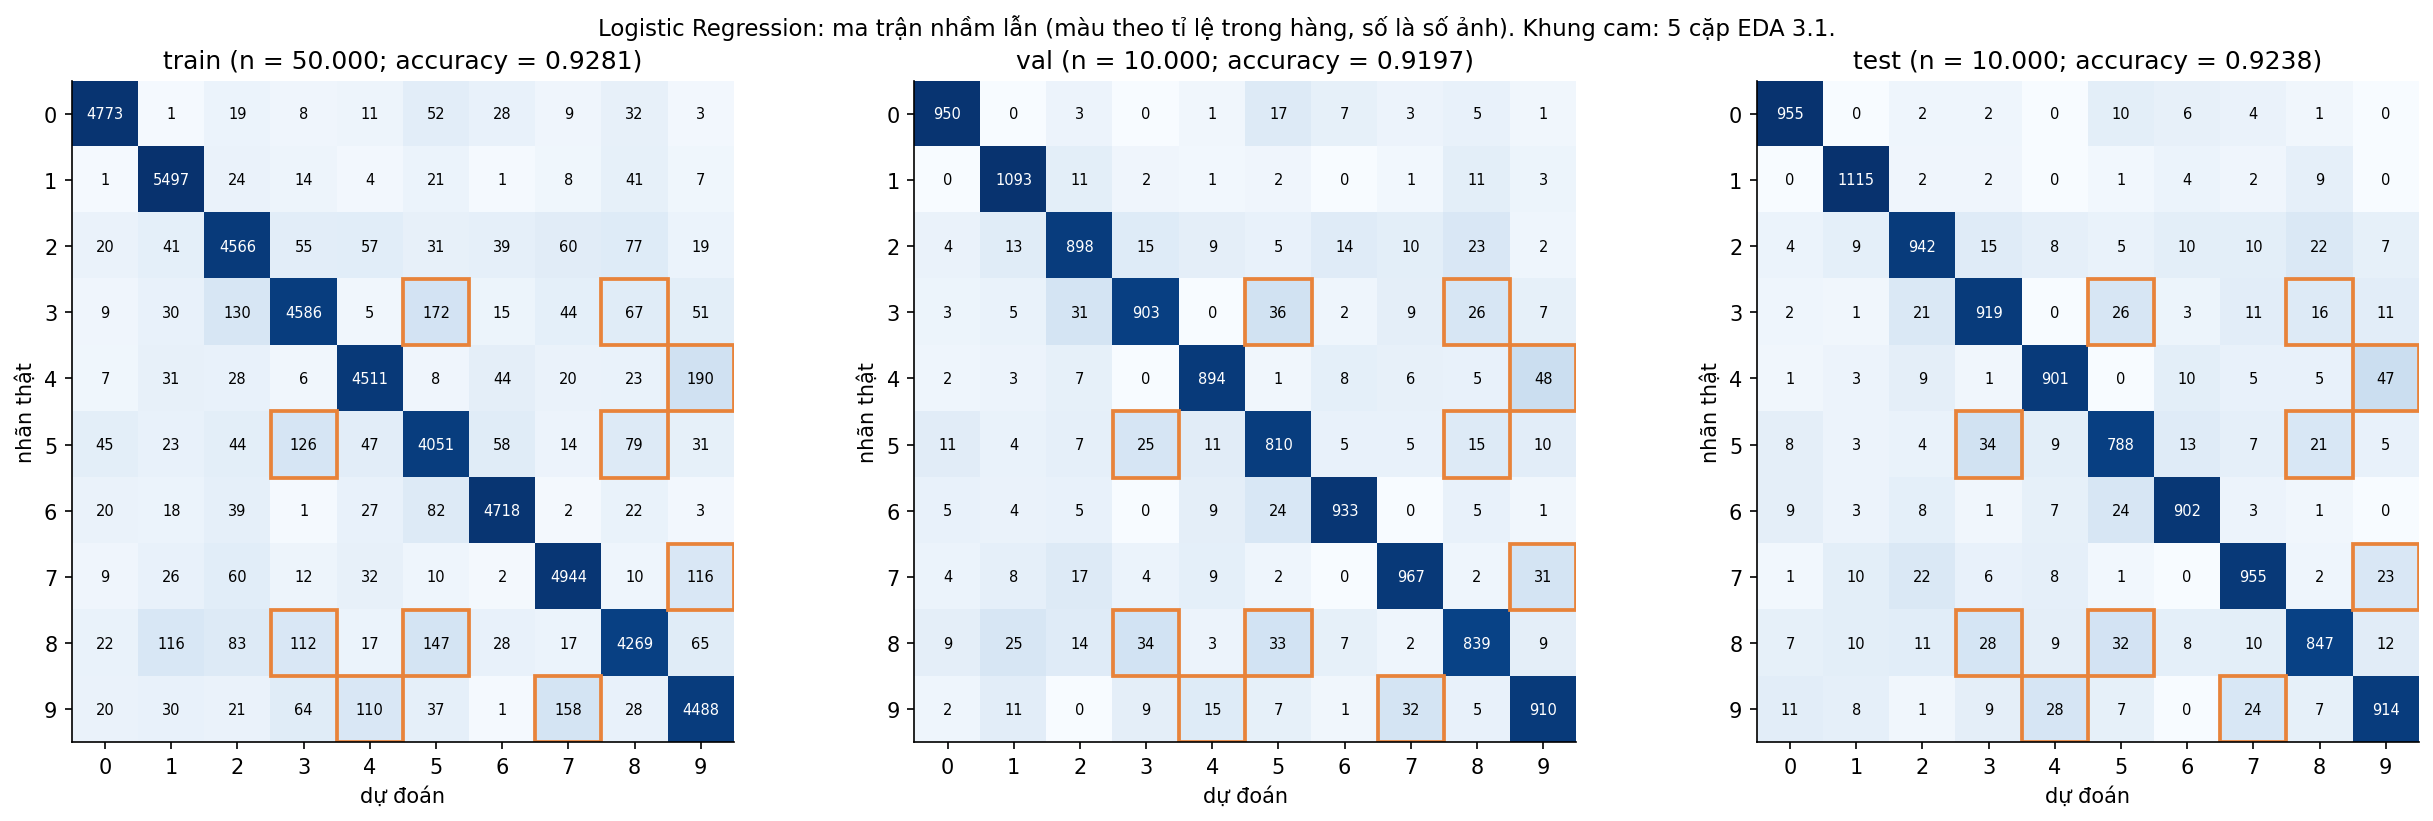

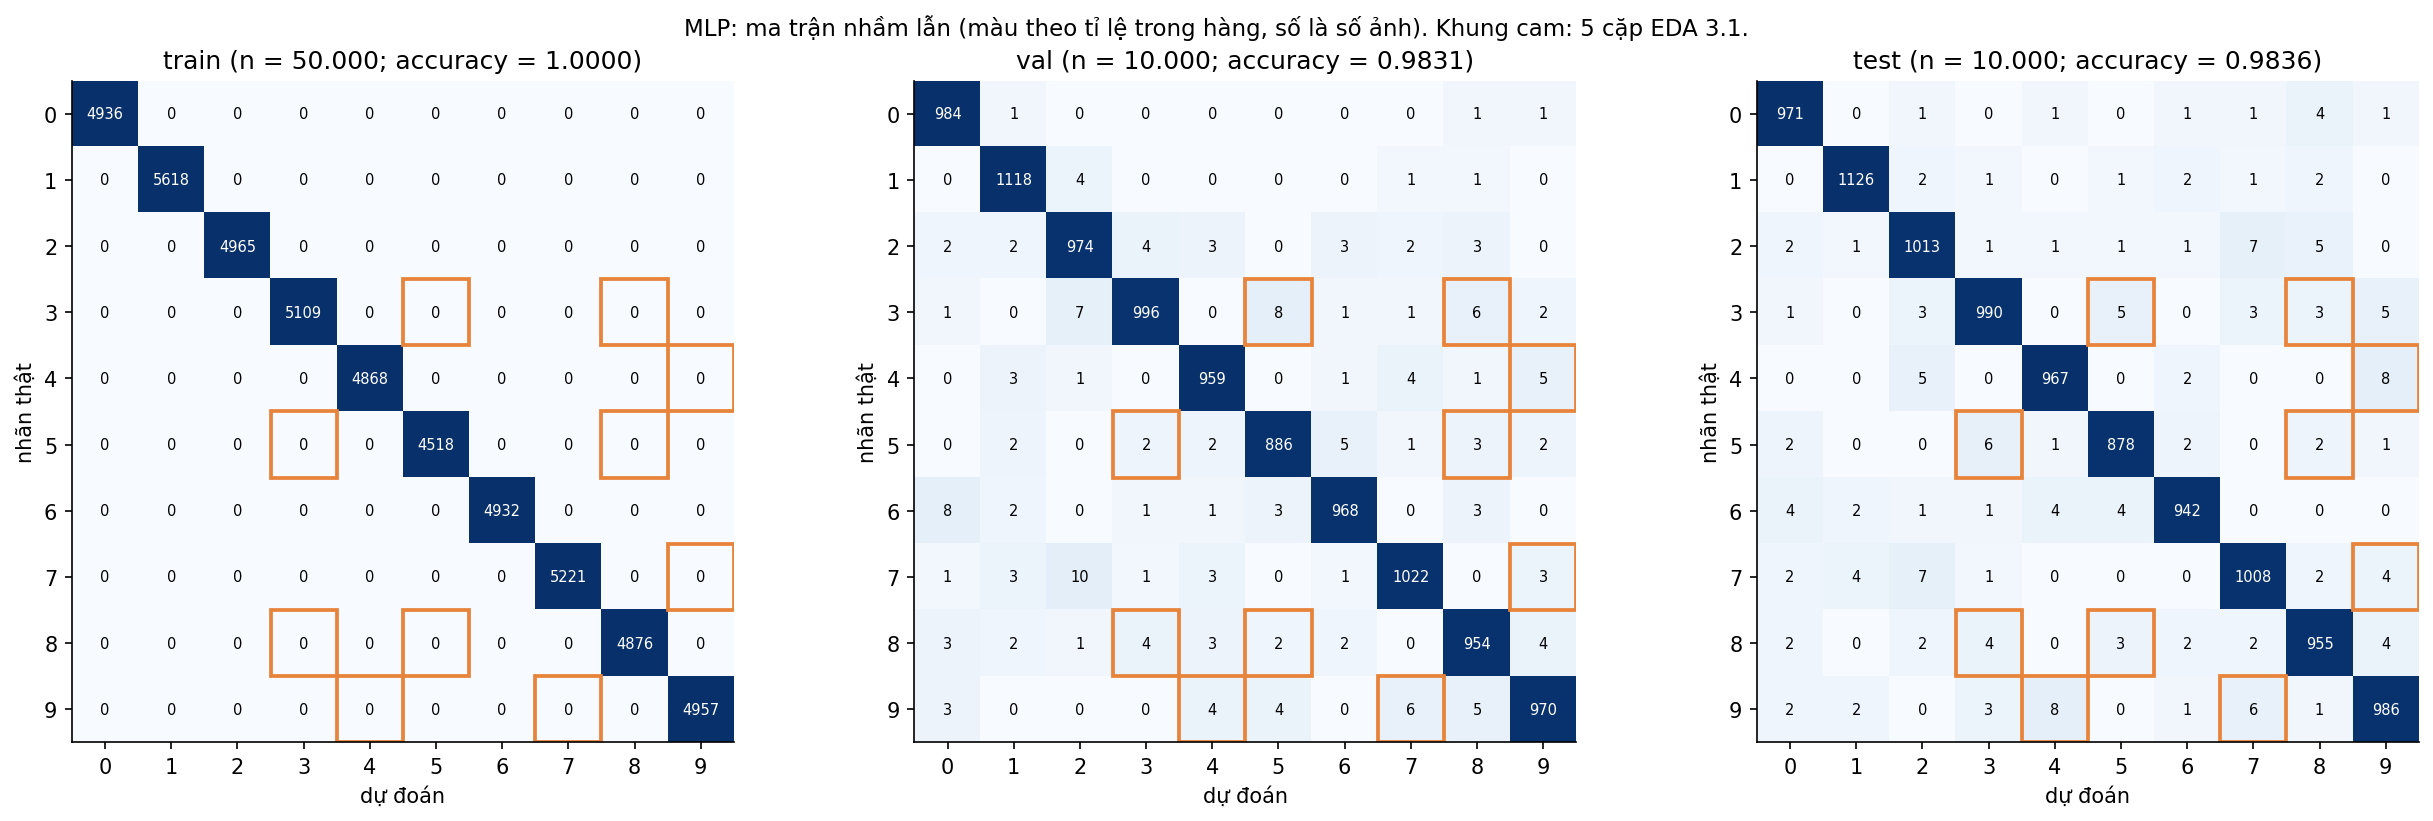

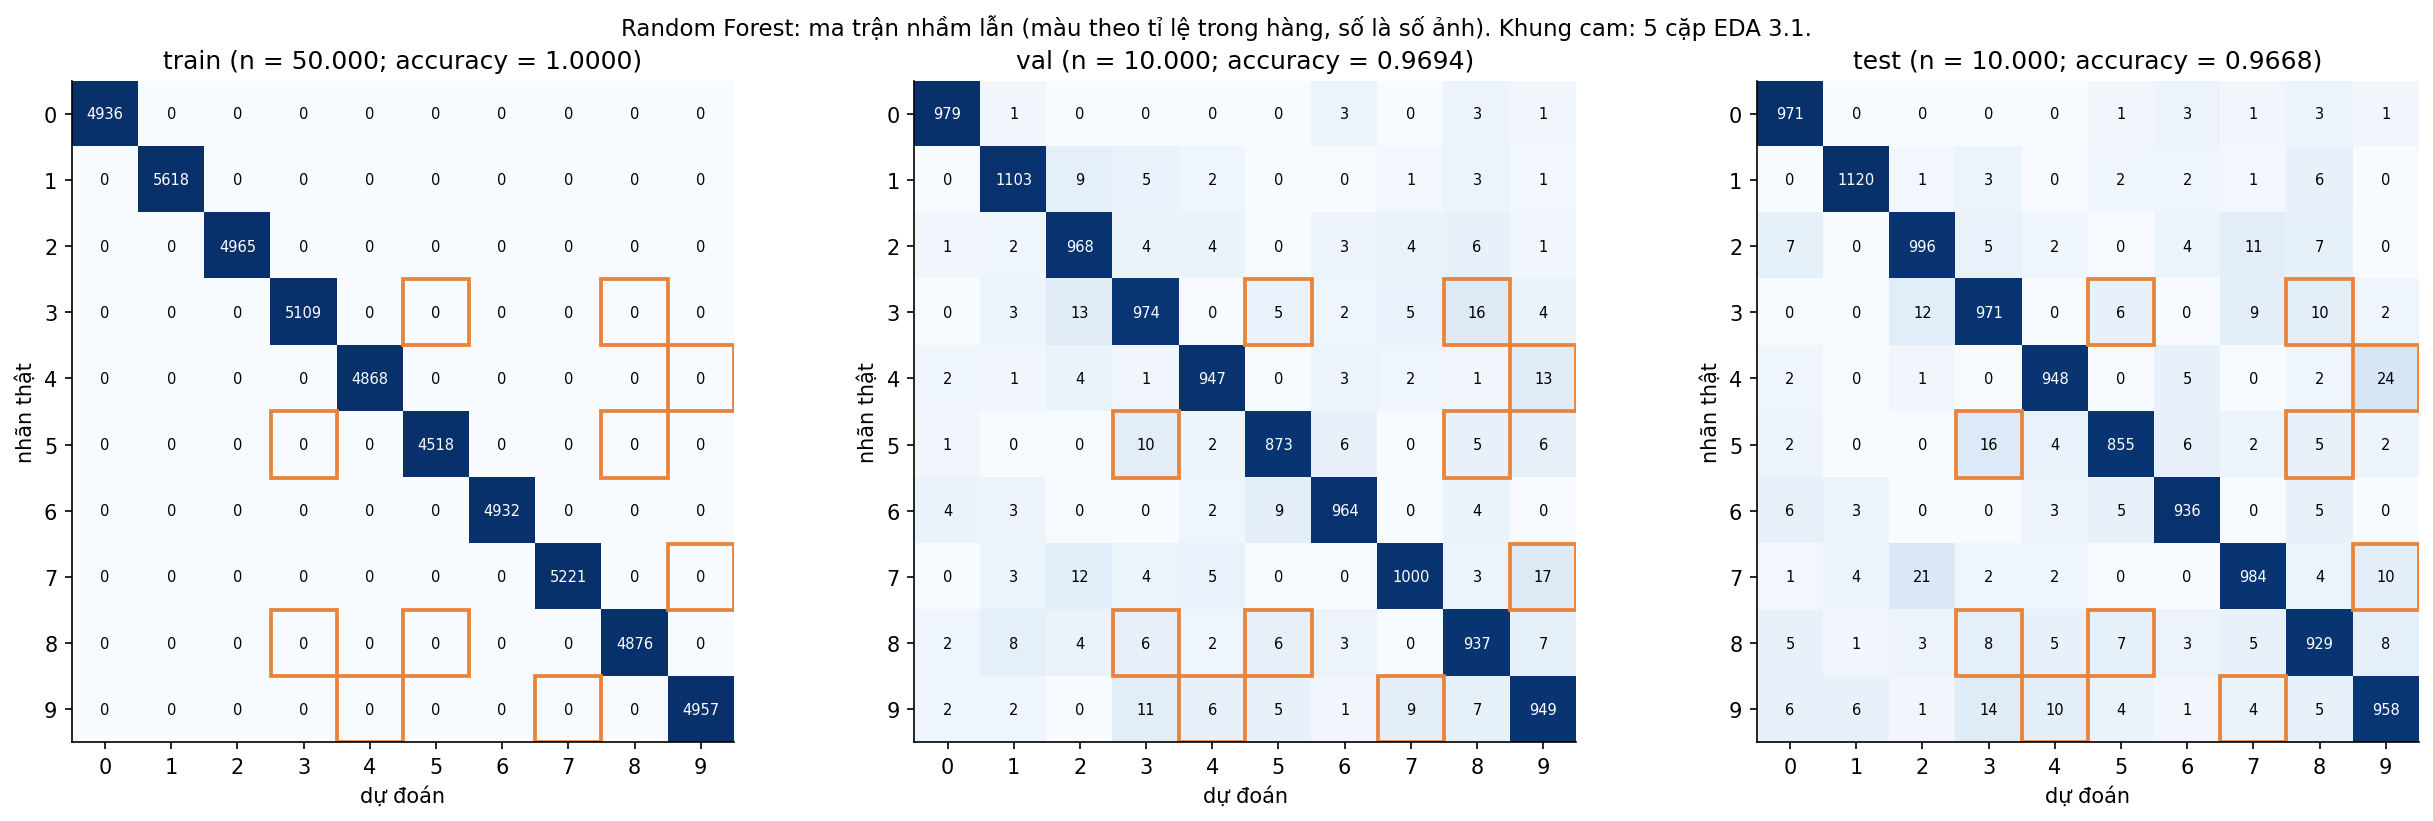

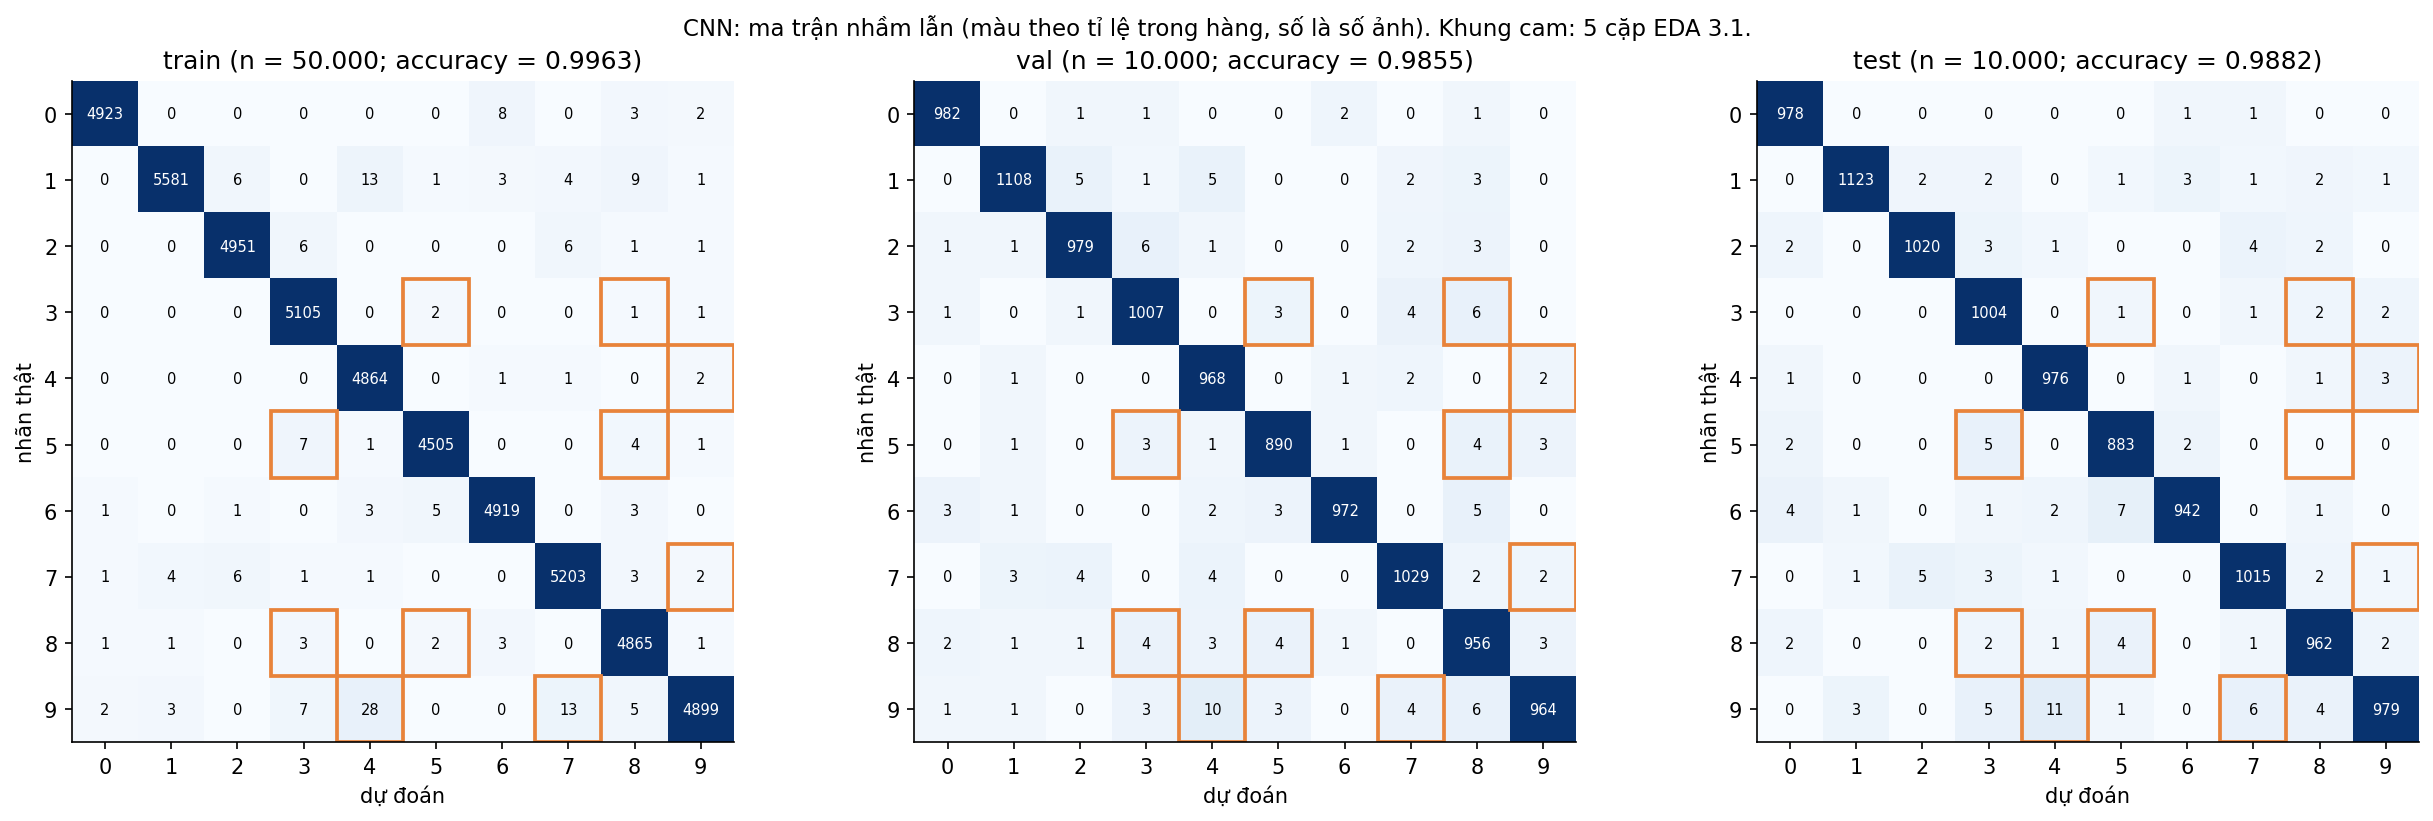

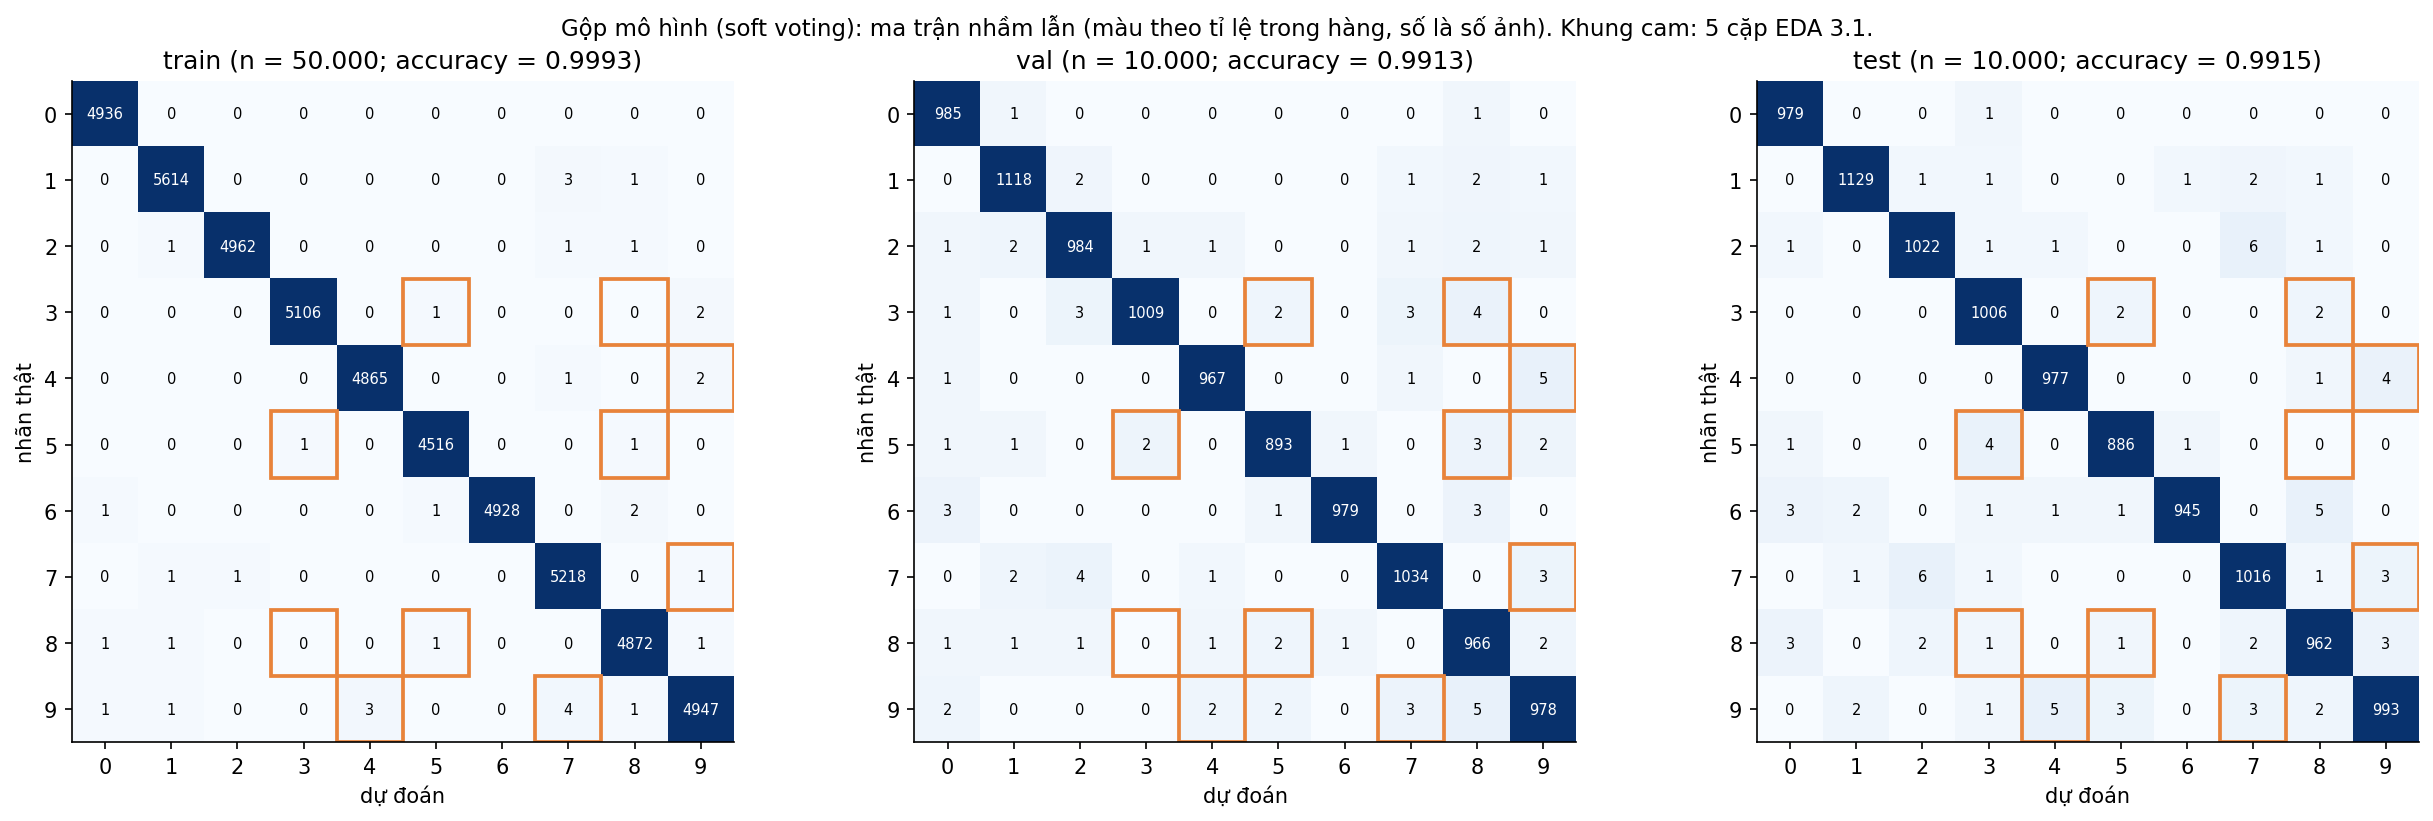

In [5]:
tmp = Path(tempfile.mkdtemp())
for k in (*MODEL_KEYS, ENSEMBLE_KEY):
    path = plot_confusion_splits(scores[k], tmp / f"{k}.png", DISPLAY_NAMES[k])
    display(Image(filename=str(path), width=950))

## 3. Ảnh hưởng của siêu tham số

Kết quả dò siêu tham số đọc từ `results/` (mỗi mô hình một thí nghiệm có biểu đồ; bảng số đầy đủ ở
`results/<mô hình>/log.txt`). Chạy lại: script tương ứng trong `src/experiments/`.

**Naive Bayes: hệ số làm trơn α**

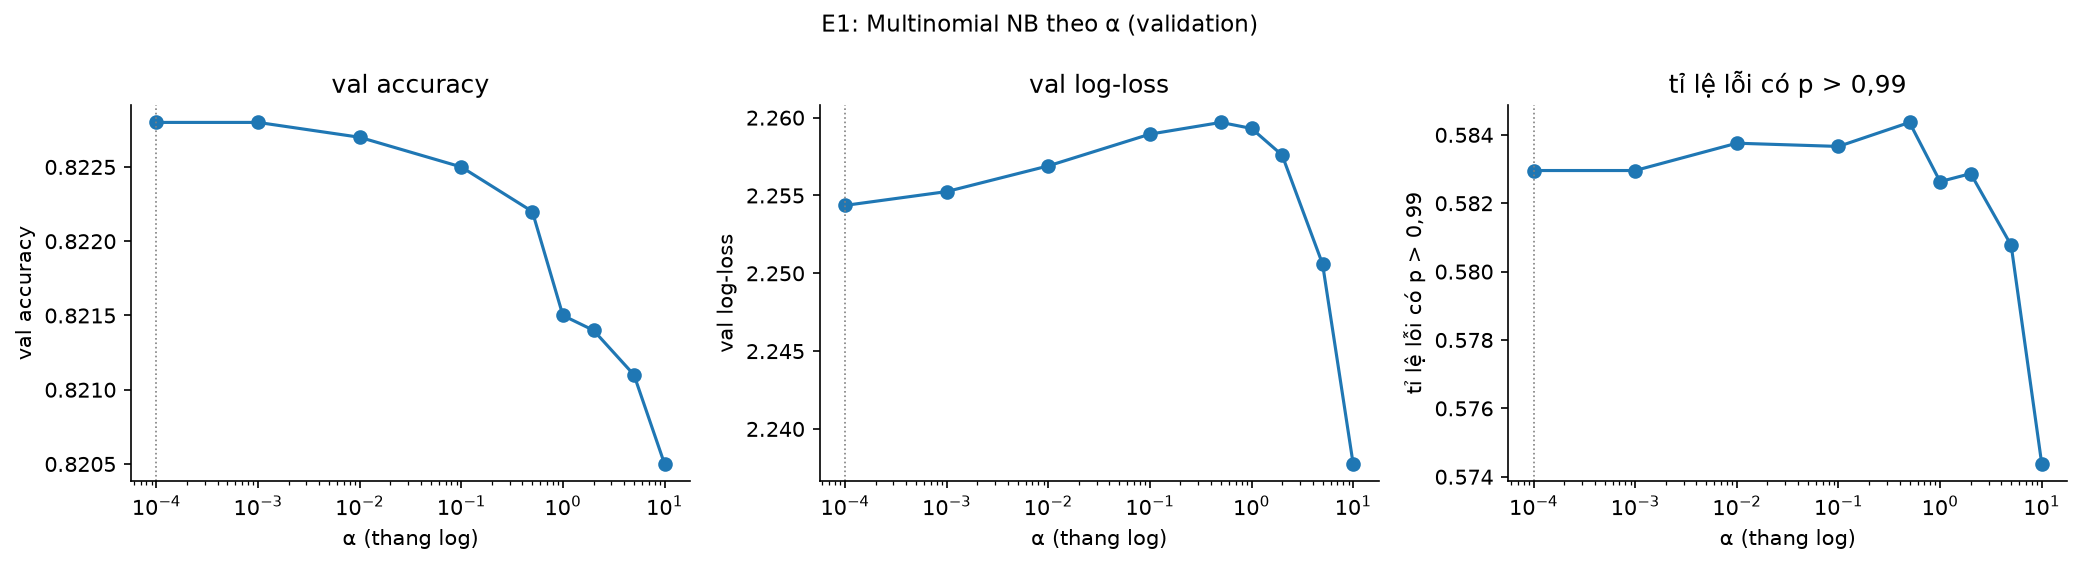

**Logistic Regression: learning rate × momentum**

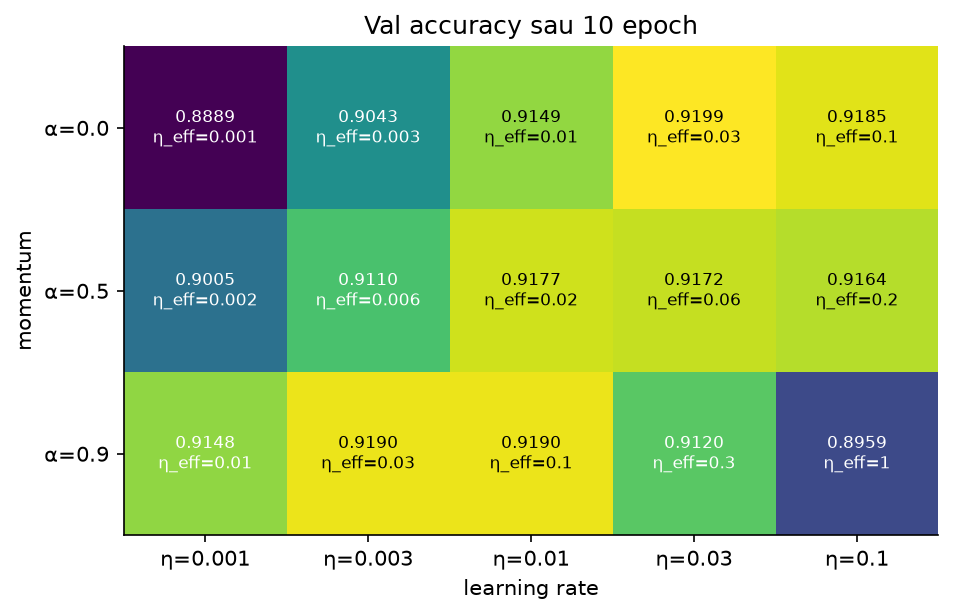

**Logistic Regression: hệ số L2**

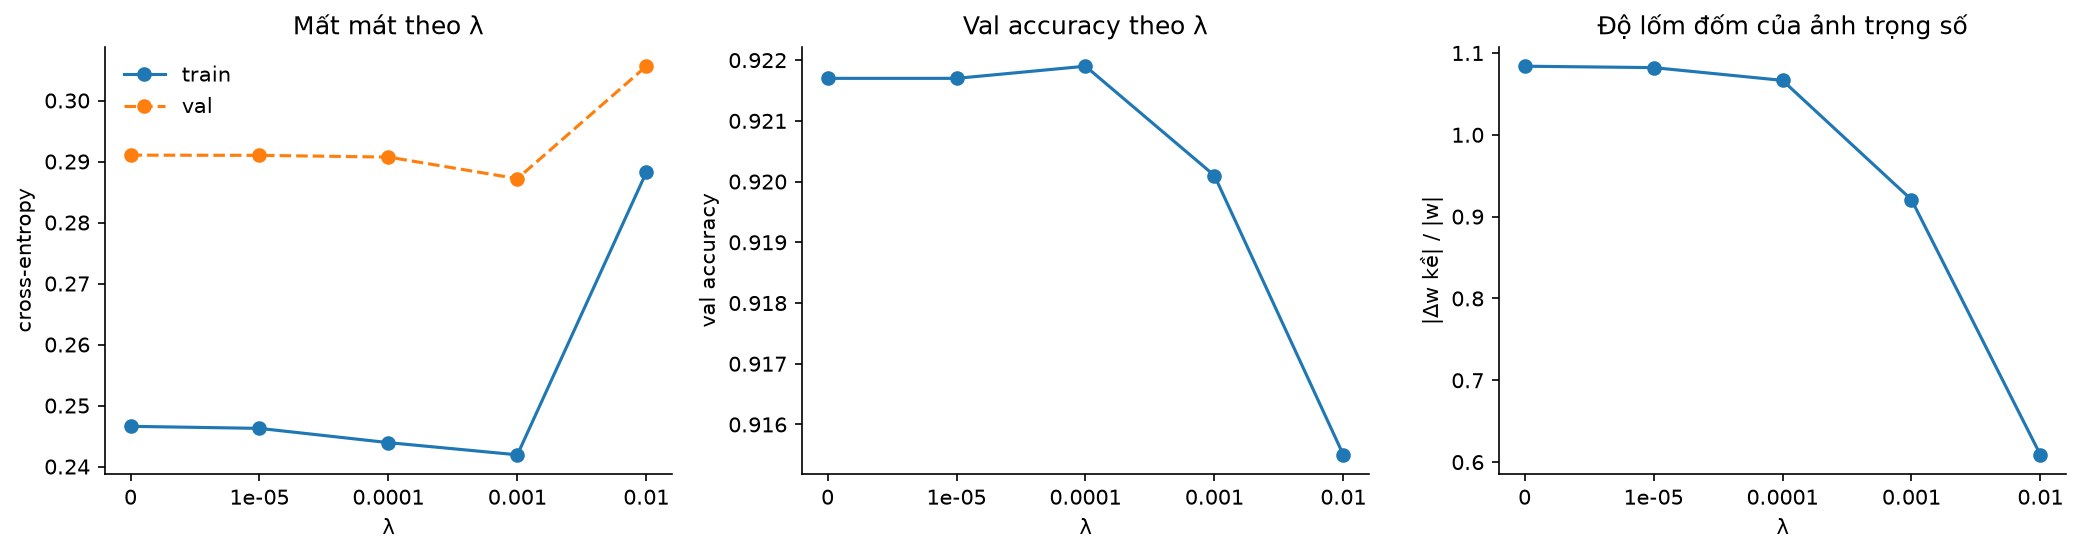

**MLP: độ rộng và độ sâu**

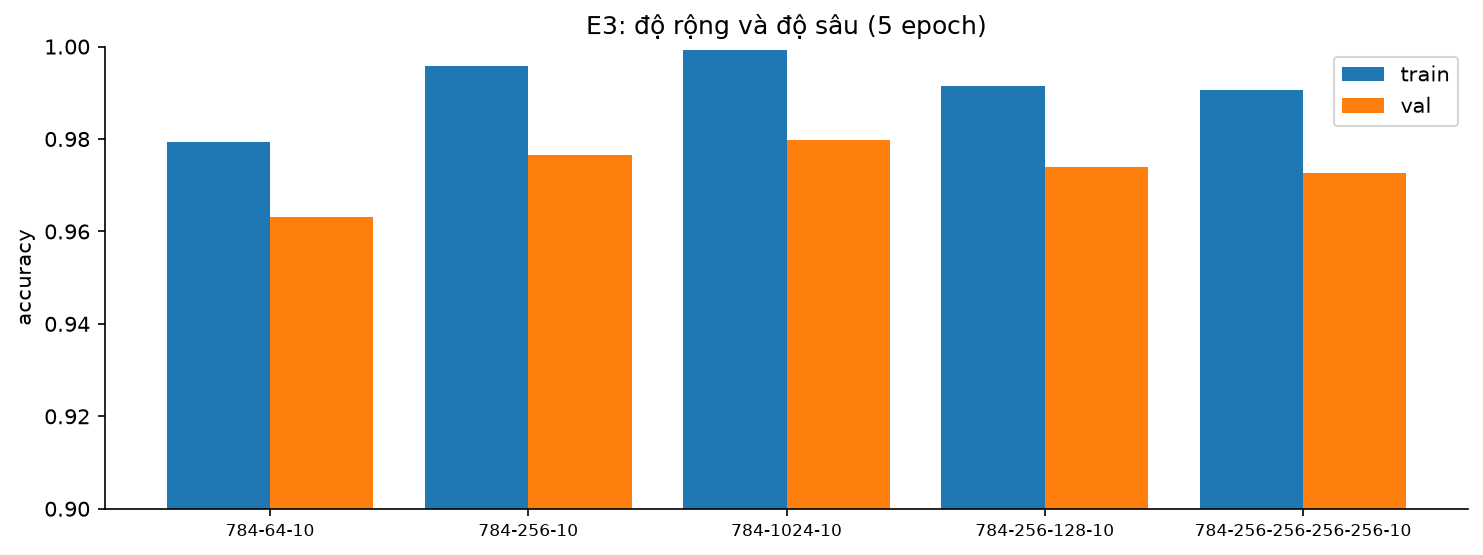

**MLP: L2 và dropout**

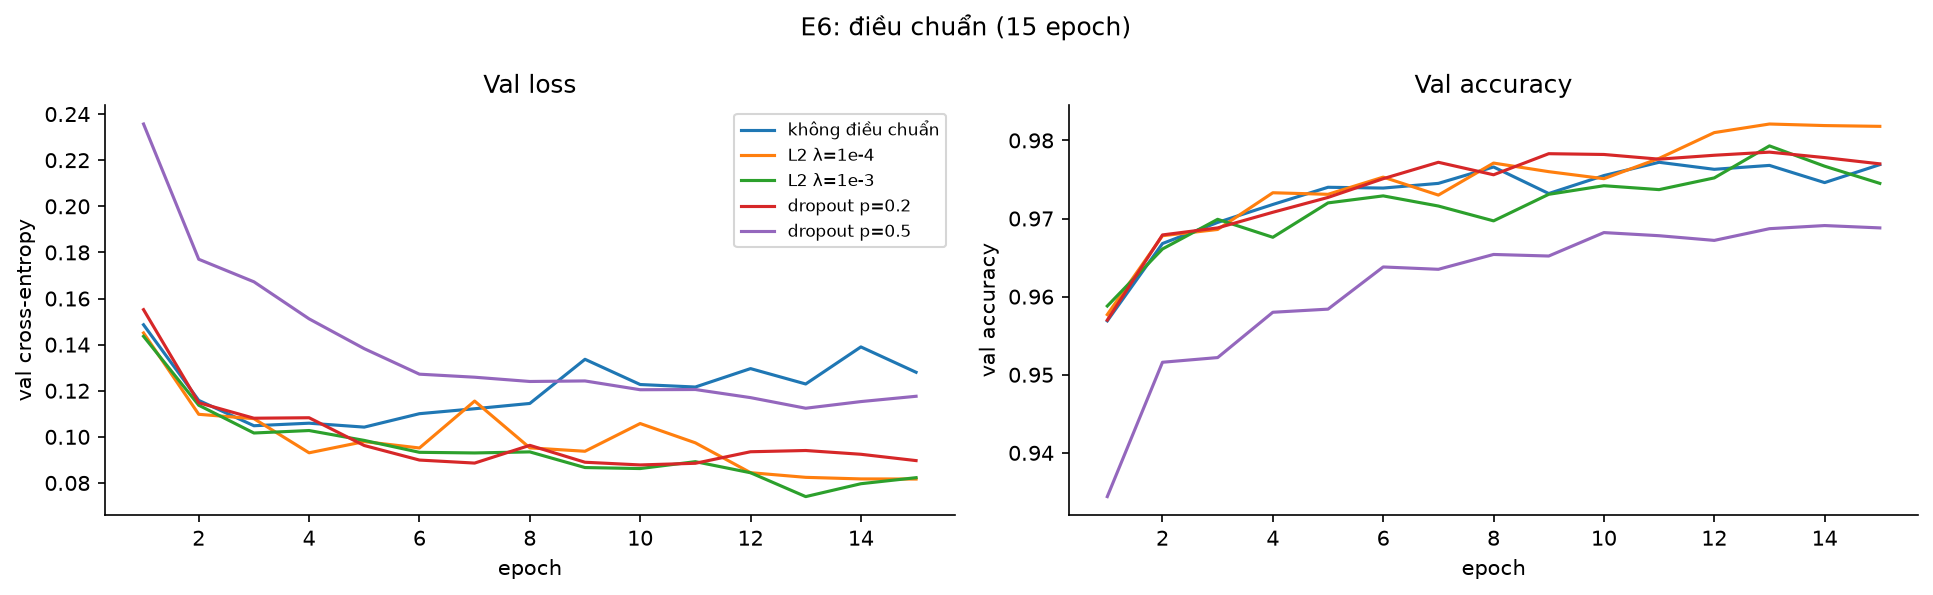

**Random Forest: số cây**

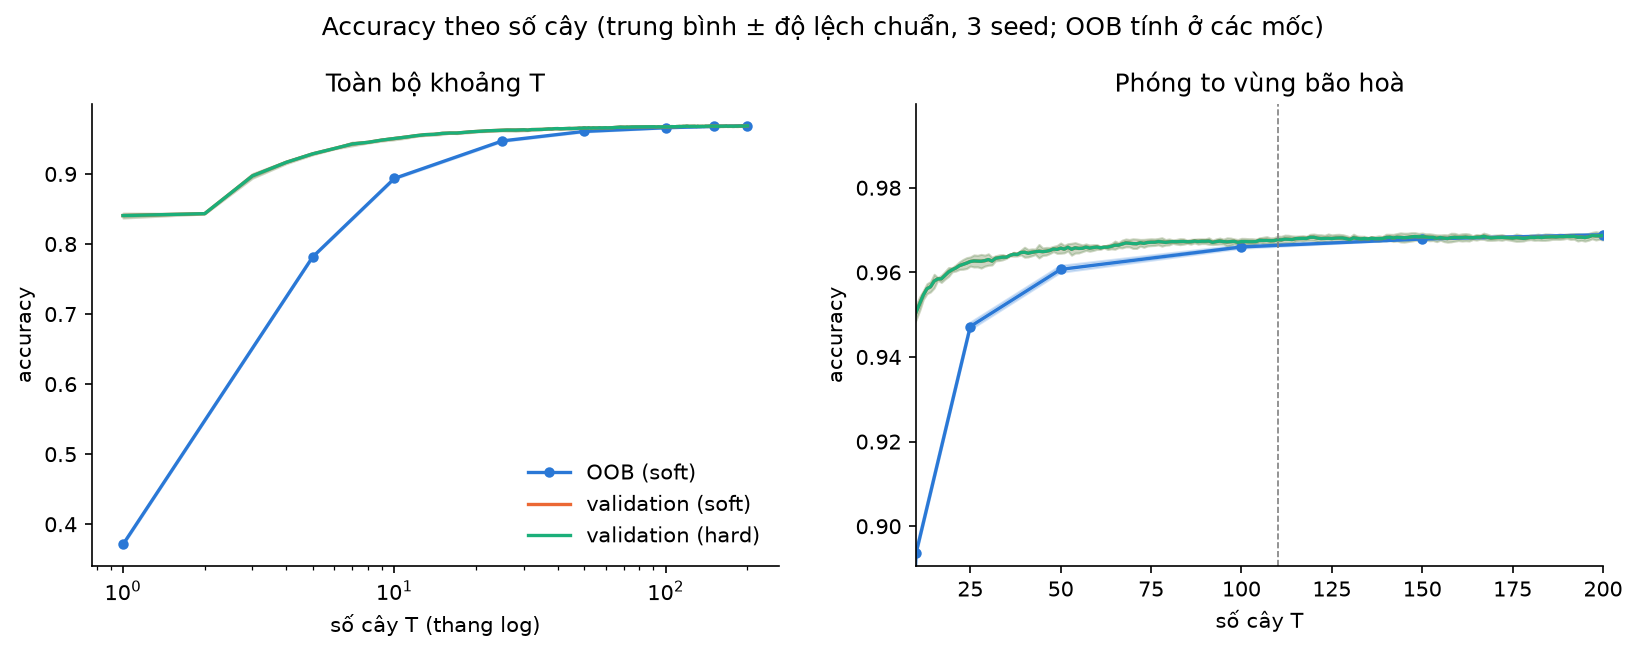

**Random Forest: max_features**

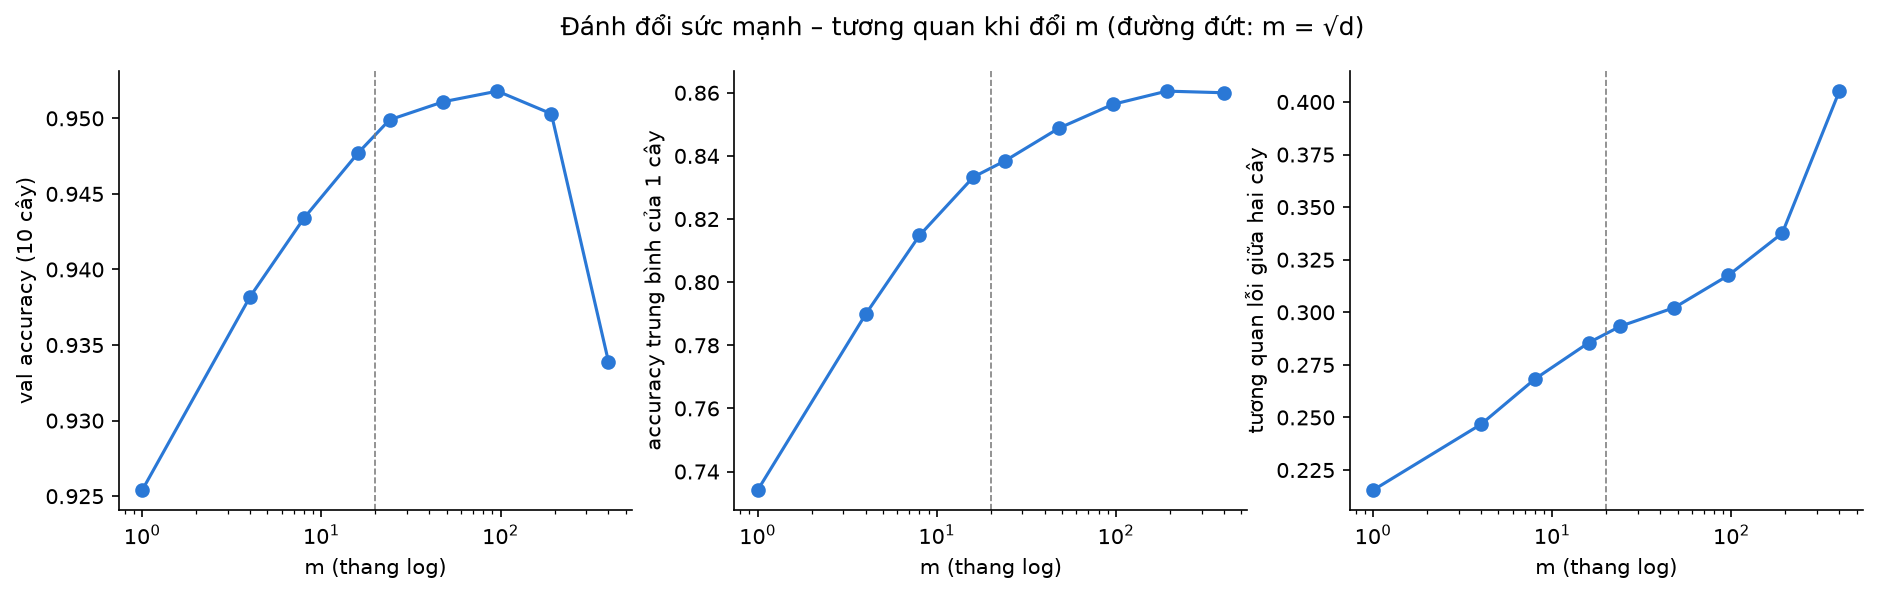

**CNN: learning rate của Adam**

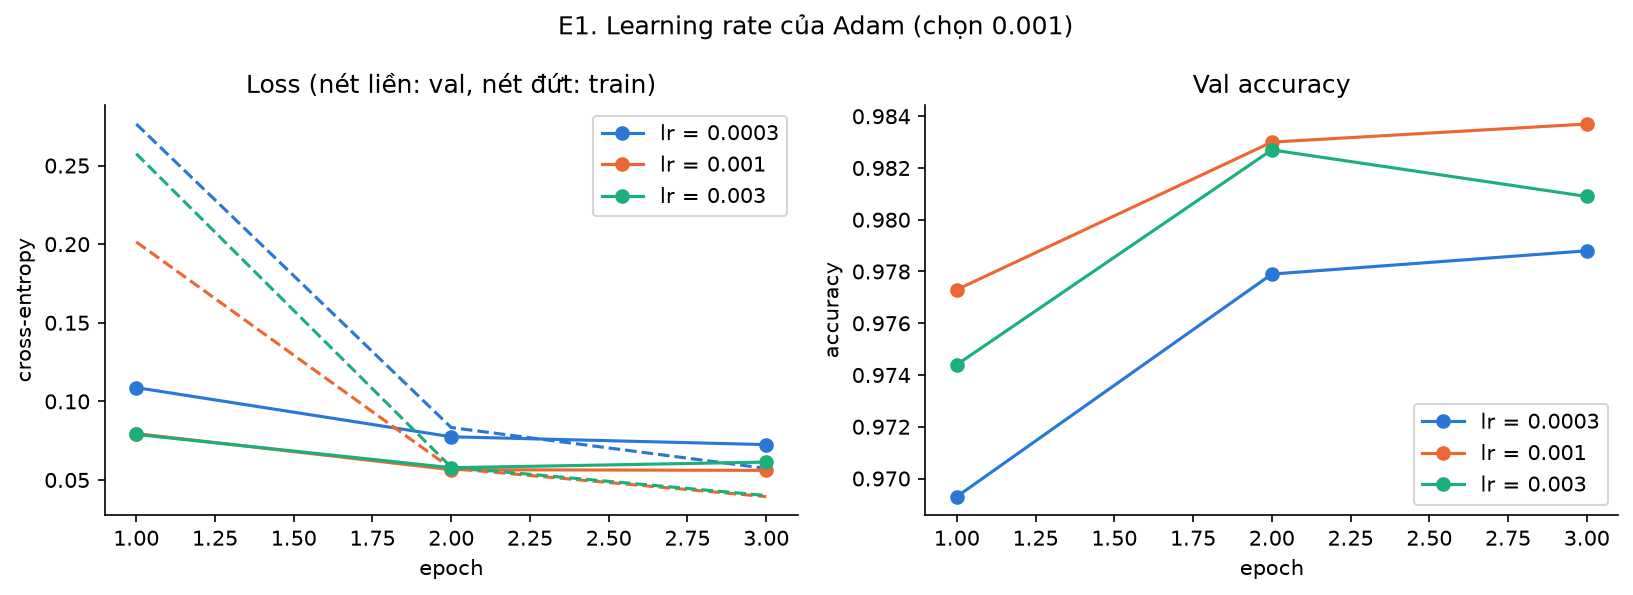

In [6]:
HP = [("naive_bayes", "hp_e1_alpha.png", "Naive Bayes: hệ số làm trơn α"),
      ("logistic_regression", "hp_e2a_lr_momentum.png", "Logistic Regression: learning rate × momentum"),
      ("logistic_regression", "hp_e3_l2.png", "Logistic Regression: hệ số L2"),
      ("mlp", "hp_e3_architecture.png", "MLP: độ rộng và độ sâu"),
      ("mlp", "hp_e6_regularization.png", "MLP: L2 và dropout"),
      ("random_forest", "hp_e3_n_trees.png", "Random Forest: số cây"),
      ("random_forest", "hp_e4_max_features.png", "Random Forest: max_features"),
      ("cnn", "hp_e1_lr.png", "CNN: learning rate của Adam")]
for key, name, title in HP:
    display(Markdown(f"**{title}**"))
    fig(key, name, width=800)

## 4. Giả thuyết H1–H4 (EDA 5.6), kiểm chứng trên validation

H1–H3 tính lại từ xác suất và dự đoán ở mục 1. H4 cần độ quan trọng hoán vị khối (vài phút đến hàng chục phút mỗi
mô hình) nên đọc từ `results/comparison/log.txt`, do `src/experiments/compare_models.py` ghi.

In [7]:
v = {k: scores[k]["val"] for k in KEYS}
y_val = splits["val"][1]
pv = {k: probabilistic_scores(y_val, proba[k]["val"]) for k in ("naive_bayes", "logistic_regression")}
nb, lr = "naive_bayes", "logistic_regression"
table(["", "Multinomial NB", "Logistic Regression"],
      [("accuracy", num(v[nb]["accuracy"]), num(v[lr]["accuracy"])),
       ("log-loss", num(pv[nb]["log_loss"]), num(pv[lr]["log_loss"])),
       ("tỉ lệ sai mà p > 0,99", f"{pv[nb]['overconfident_errors']:.2%}", f"{pv[lr]['overconfident_errors']:.2%}"),
       ("độ tự tin trung bình", num(pv[nb]["mean_confidence"]), num(pv[lr]["mean_confidence"]))])
h1 = v[lr]["accuracy"] > v[nb]["accuracy"] and pv[lr]["log_loss"] < pv[nb]["log_loss"]
print("H1 (LR chính xác hơn, xác suất đáng tin hơn NB):", "ủng hộ" if h1 else "không ủng hộ")
for k in ("random_forest", "mlp"):
    ok = v[k]["accuracy"] > v[lr]["accuracy"] and v[k]["f1_macro"] > v[lr]["f1_macro"]
    print(f"H2 ({DISPLAY_NAMES[k]} vượt LR): {'ủng hộ' if ok else 'không ủng hộ'} | acc {v[k]['accuracy']:.4f} vs "
          f"{v[lr]['accuracy']:.4f}")

rows = []
for k in KEYS:
    cm = v[k]["confusion_matrix"]
    pe = pair_errors(cm, EDA_CLOSE_PAIRS)
    rows.append((DISPLAY_NAMES[k], *pe.values(), int(cm.sum() - np.trace(cm)), f"{share_in_pairs(cm):.1%}"))
display(Markdown("**H3**: lỗi trên val ở 5 cặp EDA 3.1 (cộng hai chiều); nếu rải đều, 5 cặp chiếm 11,1% số lỗi"))
table(["Mô hình", *[f"{i}–{j}" for i, j in EDA_CLOSE_PAIRS], "tổng lỗi", "5 cặp"], rows)

|  | Multinomial NB | Logistic Regression |
|---|---|---|
| accuracy | 0,8229 | 0,9197 |
| log-loss | 2,2585 | 0,2912 |
| tỉ lệ sai mà p > 0,99 | 10.35% | 0.19% |
| độ tự tin trung bình | 0,9781 | 0,9053 |

H1 (LR chính xác hơn, xác suất đáng tin hơn NB): ủng hộ
H2 (Random Forest vượt LR): ủng hộ | acc 0.9694 vs 0.9197
H2 (MLP vượt LR): ủng hộ | acc 0.9831 vs 0.9197


**H3**: lỗi trên val ở 5 cặp EDA 3.1 (cộng hai chiều); nếu rải đều, 5 cặp chiếm 11,1% số lỗi

| Mô hình | 4–9 | 7–9 | 5–8 | 3–5 | 3–8 | tổng lỗi | 5 cặp |
|---|---|---|---|---|---|---|---|
| Tâm gần nhất (baseline) | 195 | 116 | 51 | 181 | 168 | 1952 | 36.4% |
| Naive Bayes | 246 | 127 | 116 | 125 | 111 | 1771 | 40.9% |
| Logistic Regression | 63 | 63 | 48 | 61 | 60 | 803 | 36.7% |
| MLP | 9 | 9 | 5 | 10 | 10 | 169 | 25.4% |
| Random Forest | 19 | 26 | 11 | 15 | 22 | 306 | 30.4% |
| CNN | 12 | 6 | 8 | 6 | 10 | 145 | 29.0% |
| Gộp mô hình (soft voting) | 7 | 6 | 5 | 4 | 4 | 87 | 29.9% |

H4 (số đo CHUNG cho mọi mô hình): accuracy giảm khi hoán vị khối 4×4 trên val. Spearman với tổng Fisher của khối; ủng hộ khi ρ ≥ 0.7 ở mọi mô hình:
  Tâm gần nhất (baseline)    ρ = 0.813 | khối quan trọng nhất làm giảm acc 0.0322
  Multinomial Naive Bayes    ρ = 0.900 | khối quan trọng nhất làm giảm acc 0.0361
  Logistic Regression        ρ = 0.914 | khối quan trọng nhất làm giảm acc 0.0846
  MLP                        ρ = 0.880 | khối quan trọng nhất làm giảm acc 0.0490
  Random Forest              ρ = 0.876 | khối quan trọng nhất làm giảm acc 0.0535
  CNN                        ρ = 0.930 | khối quan trọng nhất làm giảm acc 0.0488
  H4: ủng hộ (ρ khối của các mô hình từ 0.876 đến 0.914; không tính mốc tâm gần nhất và hướng nâng cao)


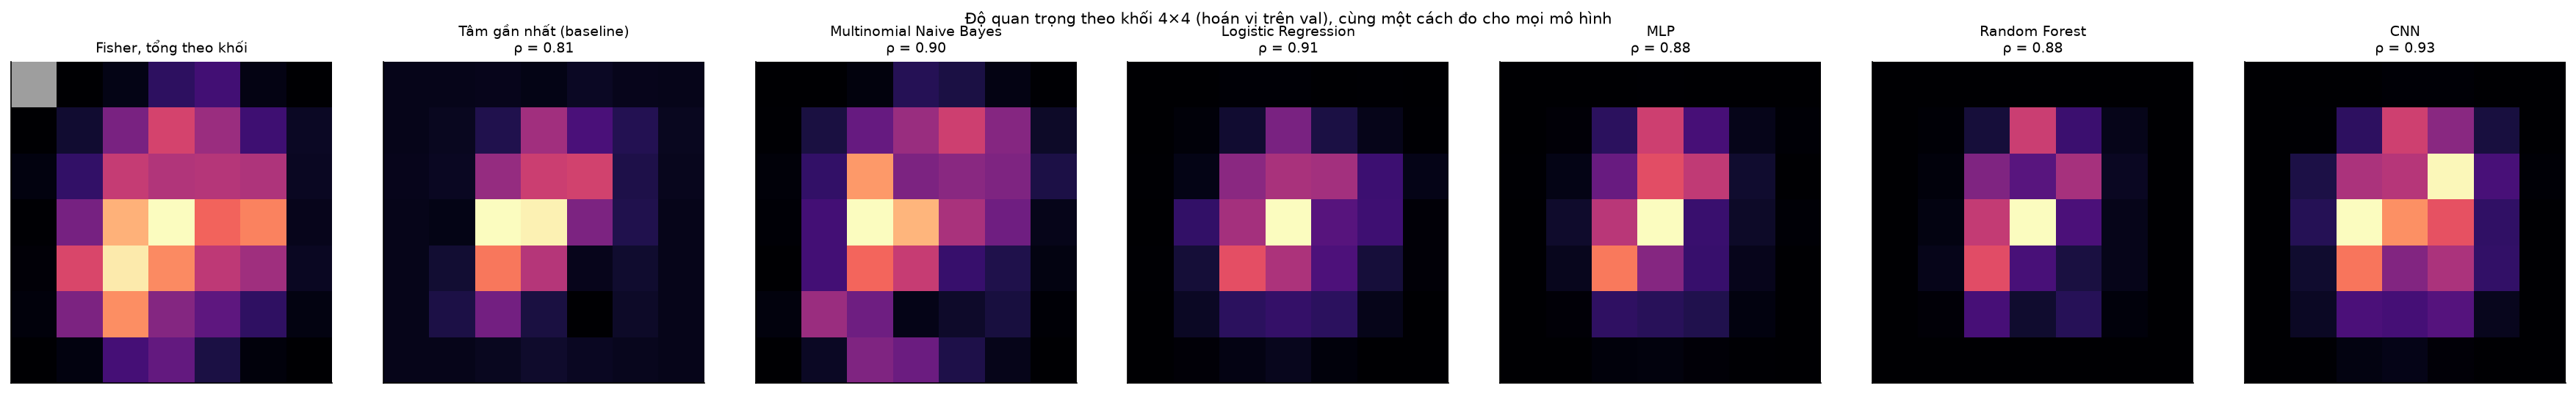

In [8]:
log = (RESULTS_DIR / "comparison" / "log.txt").read_text(encoding="utf-8")
print(log[log.index("H4 (số đo CHUNG"):log.index("Đối chiếu scikit-learn")].strip())
fig("comparison", "cmp_block_importance.png")

## 5. So sánh chung (hình của `compare_models`)

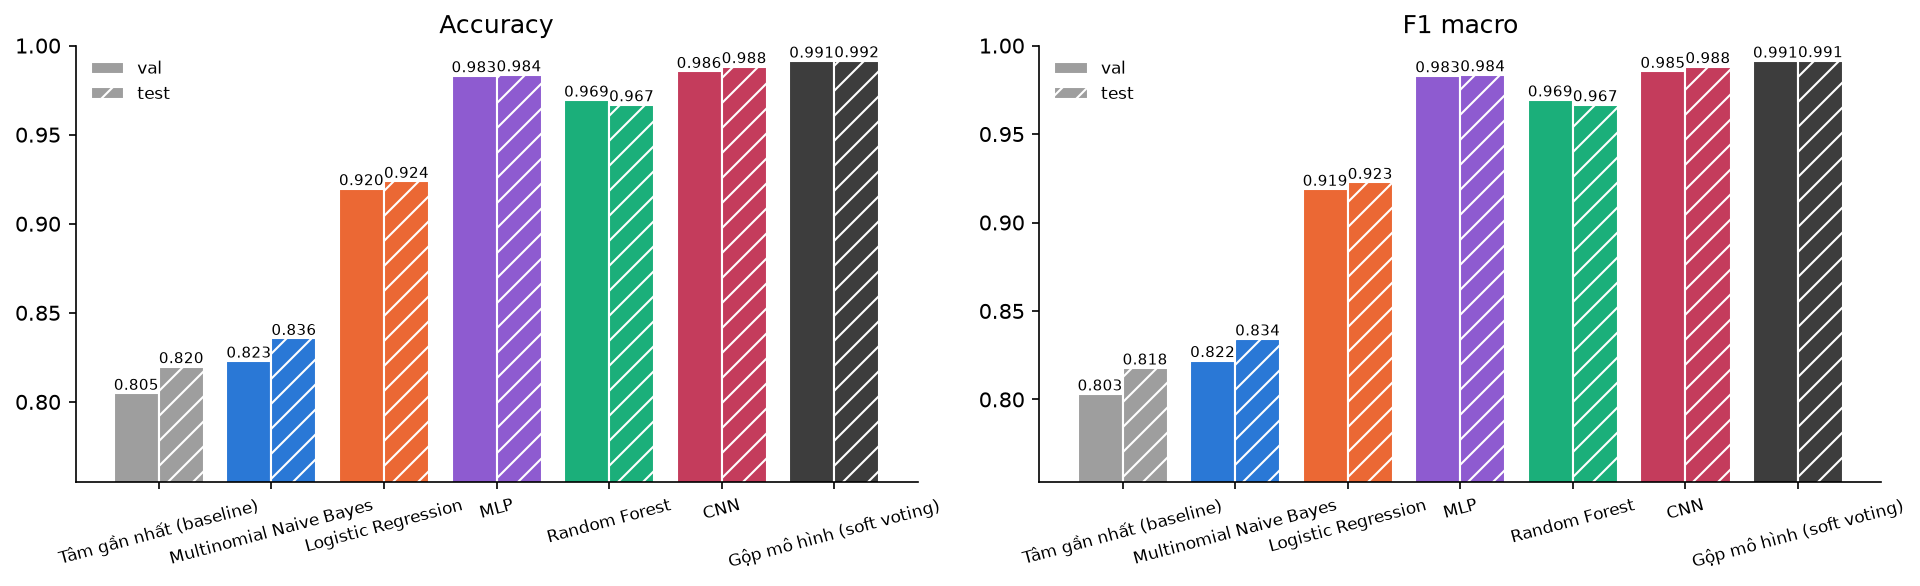

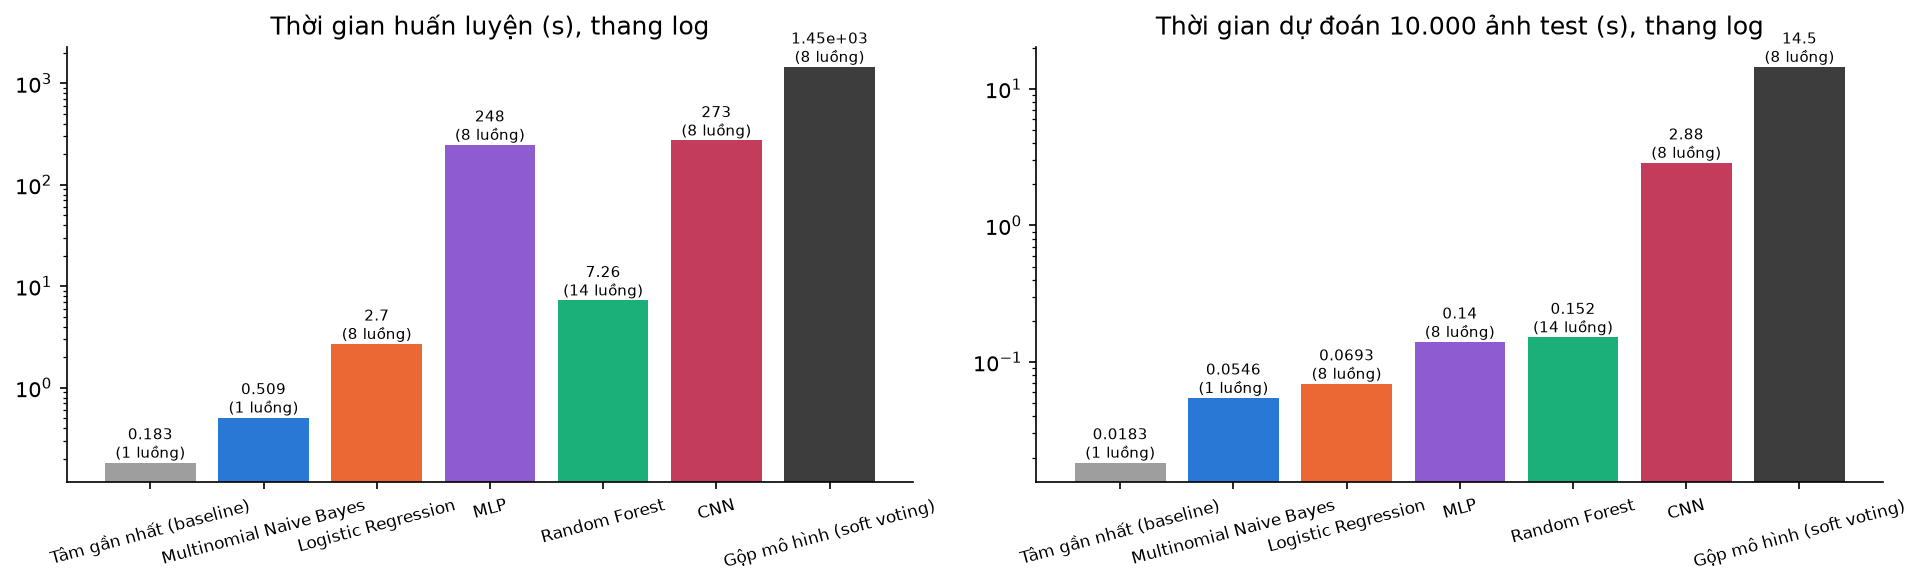

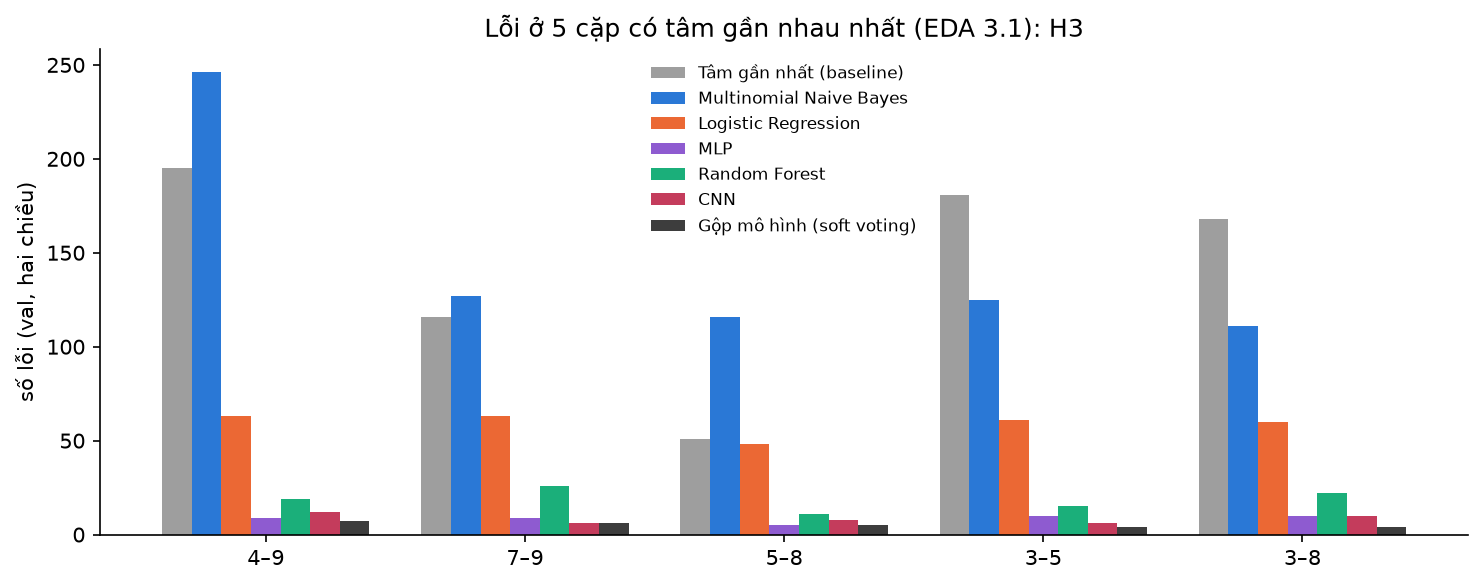

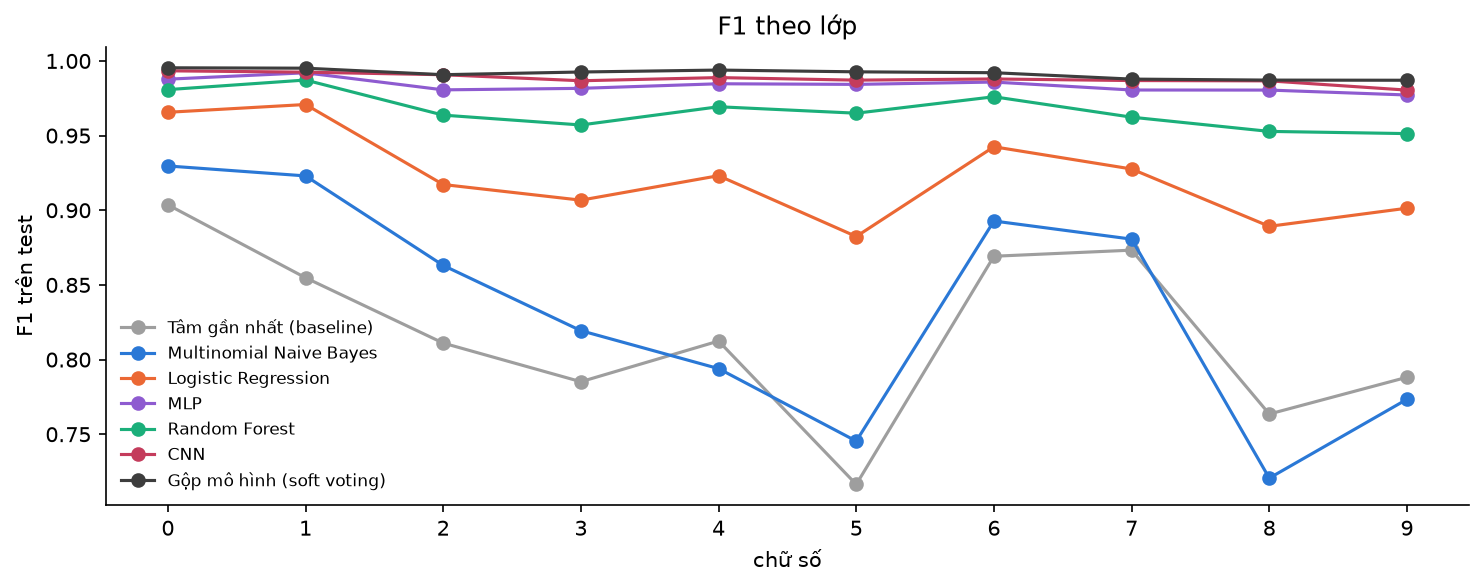

In [9]:
for name in ("cmp_metrics.png", "cmp_time.png", "cmp_pair_errors.png", "cmp_per_class_f1.png"):
    fig("comparison", name)

## 6. Đối chiếu với thư viện

Đề cho phép scikit-learn / PyTorch để đối chiếu: cùng đặc trưng, cùng siêu tham số với mô hình cuối của nhóm
(`src/experiments/sklearn_reference.py`, `torch_reference.py`). Cột "tự cài" lấy từ mục 2 ở trên.

In [10]:
ref = json.loads((RESULTS_DIR / "sklearn_reference" / "summary.json").read_text(encoding="utf-8"))
table(["Mô hình", "test acc tự cài", "test acc sklearn", "chênh", "fit tự cài (s)", "fit sklearn (s)"],
      [(DISPLAY_NAMES[k], num(scores[k]["test"]["accuracy"]), num(r["test"]["accuracy"]),
        f"{scores[k]['test']['accuracy'] - r['test']['accuracy']:+.4f}".replace(".", ","),
        num(r["ours_fit_time"], 1), num(r["fit_time"], 1)) for k, r in ref.items()])
print((RESULTS_DIR / "torch_reference" / "log.txt").read_text(encoding="utf-8").strip())

| Mô hình | test acc tự cài | test acc sklearn | chênh | fit tự cài (s) | fit sklearn (s) |
|---|---|---|---|---|---|
| Naive Bayes | 0,8356 | 0,8356 | +0,0000 | 0,5 | 2,9 |
| Logistic Regression | 0,9238 | 0,9167 | +0,0071 | 2,7 | 7,0 |
| MLP | 0,9836 | 0,9823 | +0,0013 | 247,7 | 574,4 |

Cấu hình (results/cnn/final_metrics.json): {'scale': 'scalar', 'channels': [16, 32], 'hidden': 128, 'lr': 0.001, 'batch_size': 128, 'max_epochs': 20, 'patience': 3} | torch 2.12.0+cpu, 8 luồng

        acc NumPy  acc torch    chênh  F1 NumPy  F1 torch  dự đoán NumPy  dự đoán torch
train      0.9963     0.9967  -0.0004    0.9963    0.9967         13.72s          2.93s
val        0.9855     0.9880  -0.0025    0.9854    0.9879          2.83s          0.66s
test       0.9882     0.9888  -0.0006    0.9881    0.9887          2.88s          0.56s

Huấn luyện: NumPy 273 s (8 epoch, giữ epoch 5) | torch 84 s (10 epoch, giữ epoch 7) | NumPy chậm hơn × 3.2
Hai bản khác khởi tạo (He chuẩn so với Kaiming đều của torch) và khác dãy ngẫu nhiên trộn mini-batch, nên chỉ kỳ vọng accuracy gần nhau (cỡ độ lệch do seed), không trùng từng ảnh.

Đã ghi results/torch_reference/summary.json và log.txt


**Phương án ensemble bị loại** (EDA 5.3): AdaBoost và Gradient Boosting của sklearn, cùng đặc trưng và số cây
với Random Forest, không tinh chỉnh; cả ba cùng là sklearn nên thời gian so được trực tiếp.

In [11]:
alt = json.loads((RESULTS_DIR / "sklearn_reference" / "ensemble_alternatives.json").read_text(encoding="utf-8"))
table(["Mô hình", "val acc", "test acc", "fit (s)", "luồng"],
      [(r["model"], num(r["val"]["accuracy"]), num(r["test"]["accuracy"]), num(r["fit_time"], 1), r["n_jobs"])
       for r in alt.values()])

| Mô hình | val acc | test acc | fit (s) | luồng |
|---|---|---|---|---|
| Random Forest (sklearn, cấu hình cuối) | 0,9694 | 0,9668 | 7,3 | 14 |
| AdaBoost (sklearn; SAMME, cây sâu 3, 150 cây, lr 0,5) | 0,9047 | 0,9141 | 480,1 | 1 |
| HistGradientBoosting (sklearn; 150 vòng, lr 0,1) | 0,9752 | 0,9781 | 149,9 | 14 |

## 7. Nâng cao

**CNN so với MLP** (yêu cầu nâng cao của đề; lý do làm CNN: EDA 5.4). Tính lại trên test.

| Mô hình | val acc | test acc | lỗi test | lỗi ở 5 cặp | tham số | fit (s) | luồng |
|---|---|---|---|---|---|---|---|
| MLP | 0,9831 | 0,9836 | 164 | 49 | 814.090 | 247,7 | 8 |
| CNN | 0,9855 | 0,9882 | 118 | 35 | 206.922 | 273,1 | 8 |

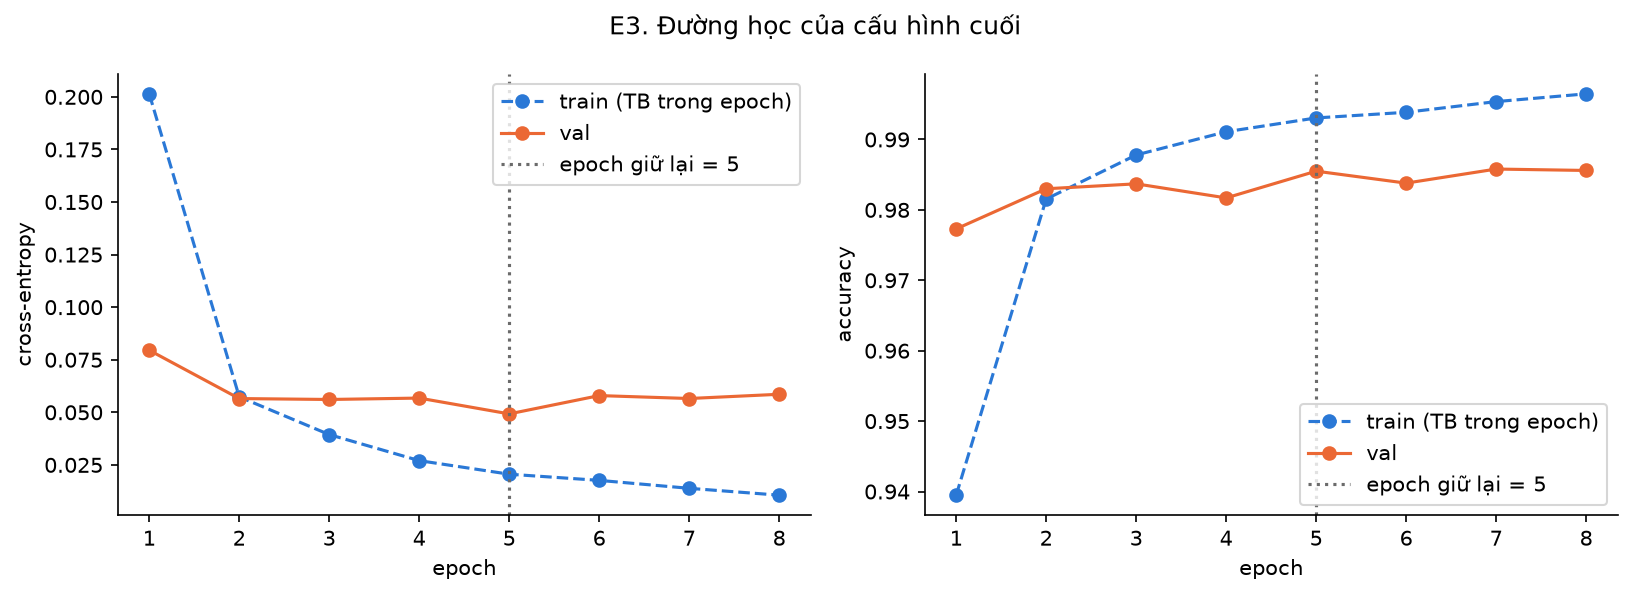

In [12]:
rows = []
for k in ("mlp", "cnn"):
    cm = scores[k]["test"]["confusion_matrix"]
    rows.append((DISPLAY_NAMES[k], num(scores[k]["val"]["accuracy"]), num(scores[k]["test"]["accuracy"]),
                 int(cm.sum() - np.trace(cm)), sum(pair_errors(cm, EDA_CLOSE_PAIRS).values()),
                 f"{recorded[k]['extra'].get('n_params', 0):,}".replace(",", "."), num(recorded[k]["fit_time"], 1),
                 recorded[k]["runtime"]["n_jobs"]))
table(["Mô hình", "val acc", "test acc", "lỗi test", "lỗi ở 5 cặp", "tham số", "fit (s)", "luồng"], rows)
fig("cnn", "eval_learning_curve.png", width=800)

**Gộp mô hình** (`src/experiments/ensemble.py`). Phương án cuối đã tính lại ở mục 1; bảng các phương án dưới đây
đọc từ `results/ensemble/summary.json`. Mọi lựa chọn làm trên validation, test chỉ để báo cáo. Lưu ý: phương án có
trọng số CNN được chọn trên chính validation (E4), nên khi so trên validation nó có lợi thế.

| Phương án | val acc | test acc | ảnh sai (test) | log-loss (test) |
|---|---|---|---|---|
| random_forest | 0,9694 | 0,9668 | 332 | 0,2180 |
| logistic_regression | 0,9197 | 0,9238 | 762 | 0,2761 |
| naive_bayes | 0,8229 | 0,8356 | 1644 | 2,0074 |
| mlp | 0,9831 | 0,9836 | 164 | 0,0537 |
| CNN đơn (CNN-s0) | 0,9855 | 0,9882 | 118 | 0,0391 |
| Soft voting: RF + MLP | 0,9826 | 0,9841 | 159 | 0,1170 |
| CNN ensemble 5 seed | 0,9912 | 0,9915 | 85 | 0,0249 |
| RF + CNN ens, cùng trọng số | 0,9901 | 0,9907 | 93 | 0,1053 |
| RF + CNN ens, CNN × 8 | 0,9913 | 0,9915 | 85 | 0,0410 |

Chọn theo val: RF + CNN ens, CNN × 8 | test tính lại: 0.9915


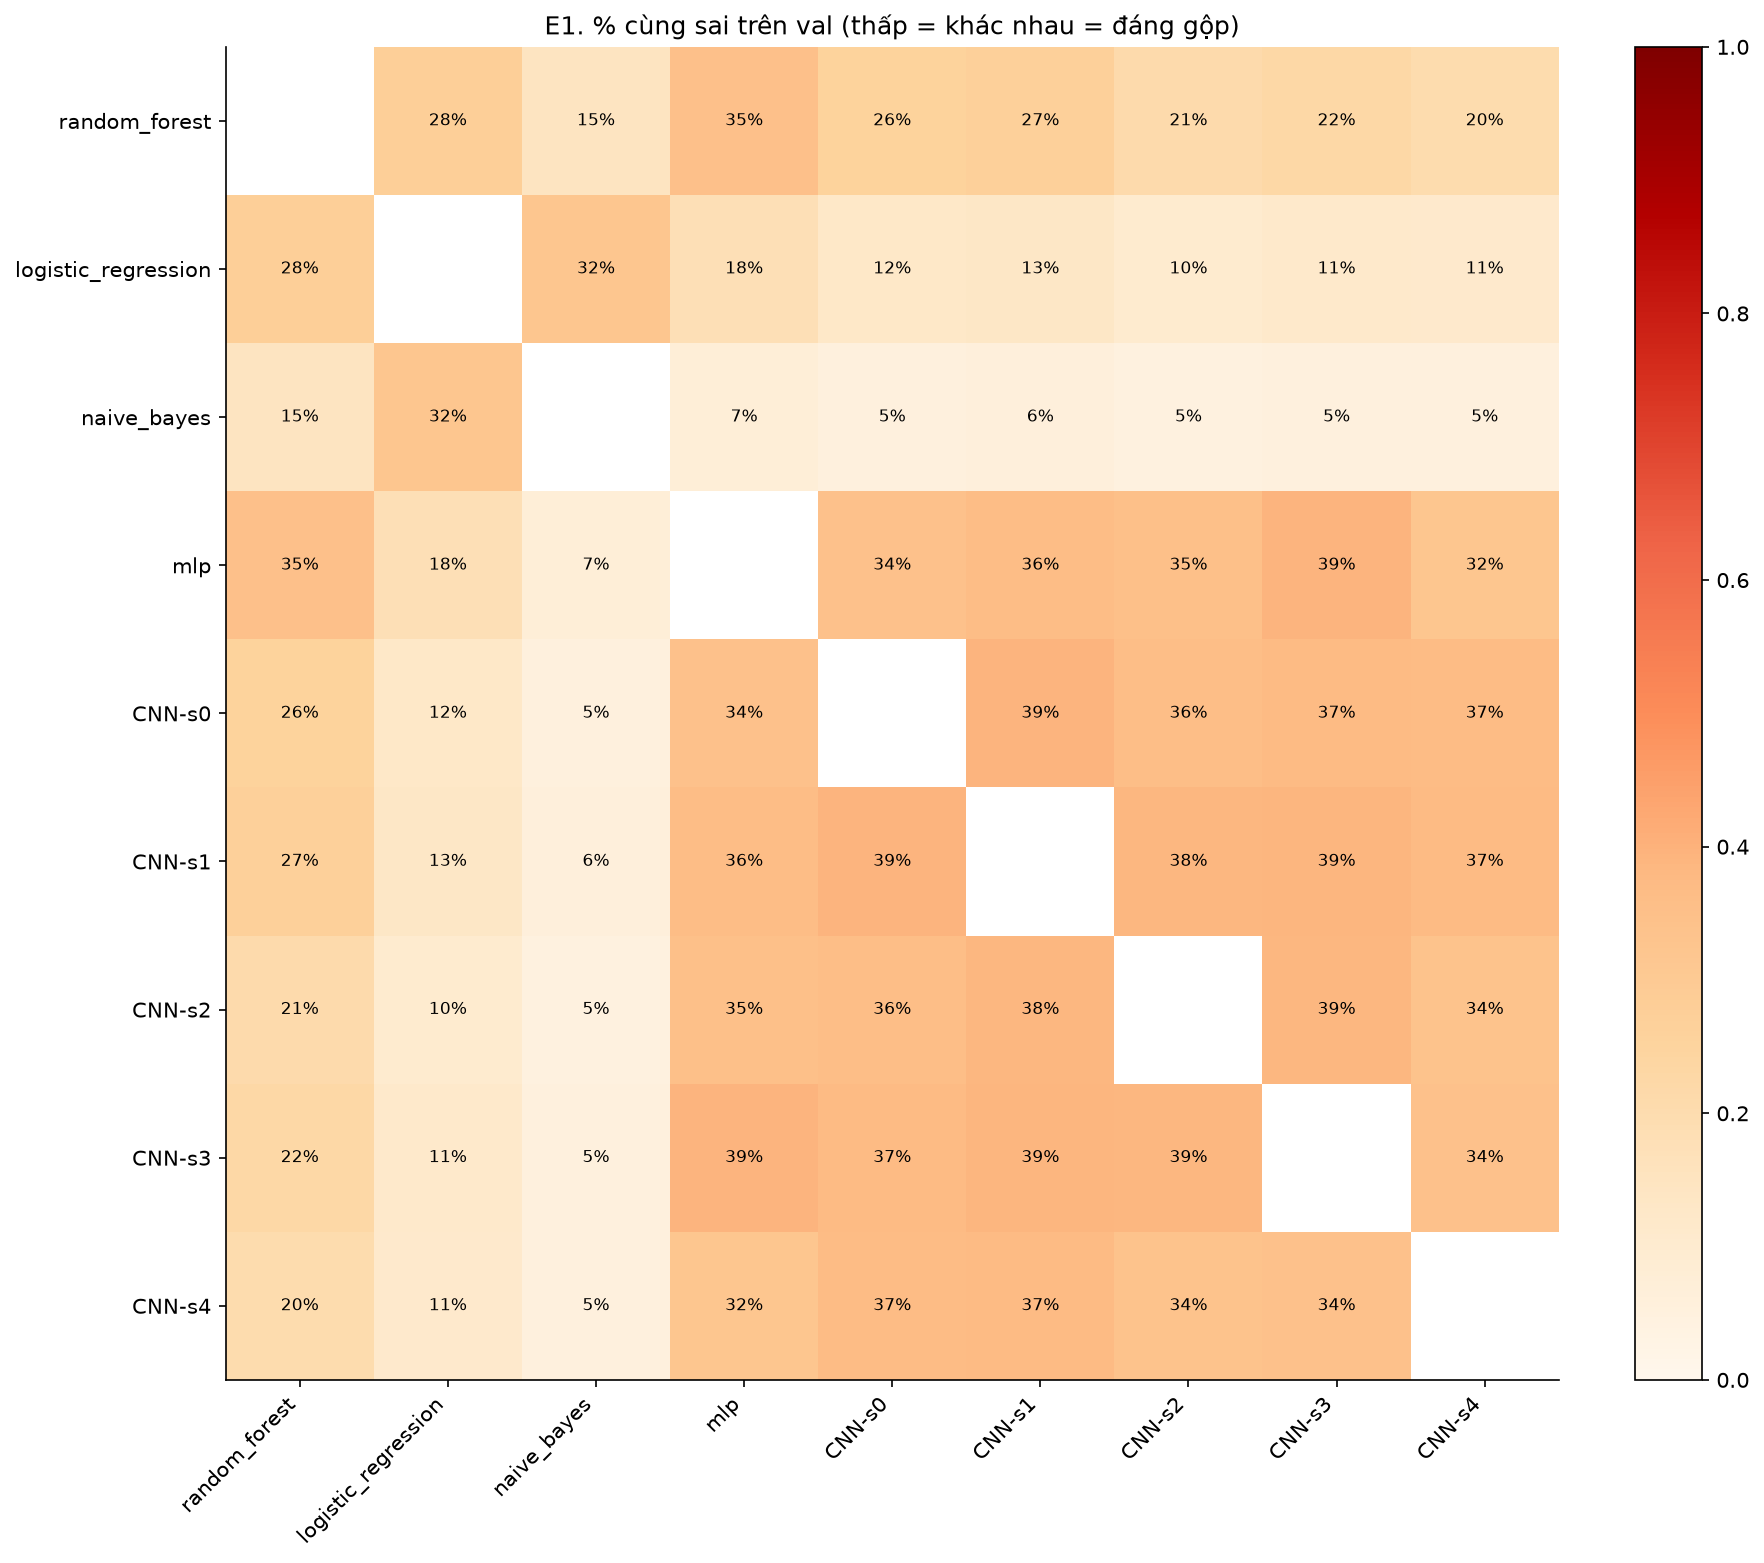

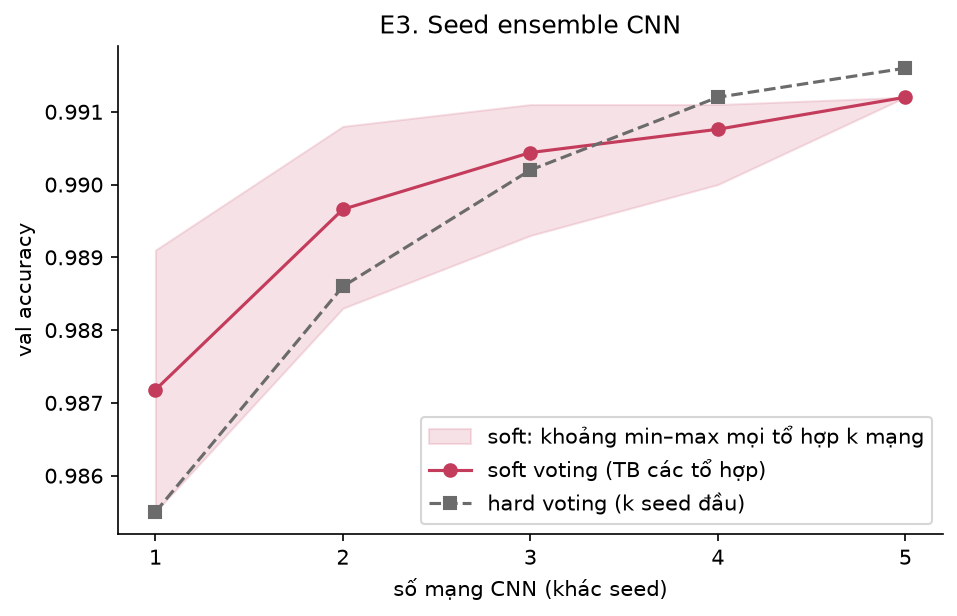

In [13]:
ens = json.loads((RESULTS_DIR / "ensemble" / "summary.json").read_text(encoding="utf-8"))
table(["Phương án", "val acc", "test acc", "ảnh sai (test)", "log-loss (test)"],
      [(r["name"], num(r["val_acc"]), num(r["test_acc"]), r["test_errors"], num(r["test_log_loss"])) for r in ens["E5"]["rows"]])
print("Chọn theo val:", recorded[ENSEMBLE_KEY]["config"]["name"], "| test tính lại:",
      f"{scores[ENSEMBLE_KEY]['test']['accuracy']:.4f}")
for name in ("div_pairs.png", "ens_seeds.png"):
    fig(ENSEMBLE_KEY, name, width=700)